# MOD550 — Assignment 3, Part I
## Support Vector Machine classification of rolling-element bearing faults

**Dataset:** Case Western Reserve University (CWRU) Bearing Data Center, seeded-fault
vibration measurements from a motor test rig.

**Problem:** from 0.17 s of drive-end vibration, name both the *location* of a bearing
fault (ball, inner race, outer race) and its *severity* (0.007", 0.014", 0.021"), or
report that the bearing is healthy. Ten classes.

---

### Group Information

| | |
|---|---|
| **Course** | MOD550 — Engineering Machine Learning with Real-World Data |
| **Assignment** | 3, Part I — Support Vector Machine Classification |
| **Group members** | *(fill in: full names of all members)* |
| **This repository belongs to** | ... |
| **Dataset used in Part I** | CWRU 12 kHz drive-end + normal baseline |
| **Dataset used in Part II** | the same windows, unchanged (the "Reading the data" cell is identical in both notebooks) |

> **How to read this notebook.** Sections *Task I.1*–*Task I.5* are the shared group
> work. The final section, *Individual Analysis*, contains only student's own
> answers and is not shared with the group.
>
> Inside each task, the word-limited report is the cell headed with its word count
> (*Discussion*, *Critical analysis*). The numbered sub-sections around it hold the code,
> figures and tables that support it.
>
> Run the two cells under *Setup* first. Everything else builds on them, and nothing in
> this notebook is imported from another file.

**Contents**

1. [Task I.1 — Engineering problem and dataset](#task-i1)
2. [Task I.2 — Data exploration and preparation](#task-i2)
3. [Task I.3 — Classification strategy and baseline](#task-i3)
4. [Task I.4 — SVM modeling](#task-i4)
5. [Task I.5 — Model evaluation and comparison](#task-i5)
6. [Individual Analysis](#individual)

In [45]:
# ---------------------------------------------------------------- environment
import os
import sys
import time
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)

# every path below is relative to the folder this notebook sits in
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

SEED = 42
np.random.seed(SEED)

# ---------------------------------------------------------------- figure style
# Fault LOCATION is nominal, so it is carried by hue. Fault SEVERITY is ordered,
# so it is carried by a light-to-dark step inside the location's own hue rather
# than by a fourth, fifth and sixth hue. Ten categorical colours would be
# unreadable and would throw away the fact that 0.007" < 0.014" < 0.021".
INK = "#44403c"
LOC_HUE = {"Normal": INK, "Ball": "#2a78d6", "Inner": "#eb6834", "Outer": "#1baf7a"}
LOC_RAMP = {
    "Ball":  ["#6ba6e4", "#2a78d6", "#17457c"],
    "Inner": ["#ef8f62", "#eb6834", "#8f3a16"],
    "Outer": ["#52c49e", "#1baf7a", "#0d6348"],
}
SIZES = ["007", "014", "021"]


def class_colour(name):
    if name == "Normal":
        return INK
    loc, size = name.split("_")
    return LOC_RAMP[loc][SIZES.index(size)]


mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b8b5ad", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e4de", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False, "figure.facecolor": "white",
})
print(f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__}")

python 3.13.7 | numpy 2.1.3 | pandas 2.2.3


### Setup: reading the data

The code cell below is the only place in this notebook that touches the data files. It
reads the 56 recordings straight from the `Data` folder next to the notebook (the exact
file list is in the README). If the folder or some files are missing, the cell downloads
them once into `Data` (about 187 MB, from the Bearing Data Center, with a public mirror as
fallback) and every later run reads them locally; setting `AUTO_DOWNLOAD = False` switches
that off. It then brings the healthy baseline from 48 kHz to 12 kHz (the reason
is Task I.2.2), cuts every recording into non-overlapping windows of 2048 samples, and
defines the split by motor load (the reason is Task I.3). Part II contains the
identical cell, which is what guarantees that both parts use the same windows and the same
split. Nothing is imported from another file, so sections can be moved freely as long as
the two cells above and below run first.

In [46]:
# ------------------------------------------------------------ reading the data
# Everything this notebook needs from disk is read in this one cell, straight from the
# Data folder next to the notebook. Nothing is imported from another file.
# If the Data folder or some of the 56 files are missing, they are downloaded once and
# kept (see AUTO_DOWNLOAD below); after that the notebook never touches the network.
import re
import shutil
import urllib.error
import urllib.parse
import urllib.request
from dataclasses import dataclass
from pathlib import Path

import scipy.io as sio
from scipy.signal import decimate

# ---- acquisition constants ---------------------------------------------------------
FS = 12_000               # Hz, the sampling rate every signal is brought to
FS_NORMAL_RAW = 48_000    # Hz, the rate the healthy baseline was recorded at
WINDOW = 2048             # samples per window = 170.7 ms = about 5 shaft turns

# The target is fault LOCATION and SEVERITY together: ten classes. The 0.028" fault size
# is left out because the Bearing Data Center only published it for Ball and Inner-Race
# faults at 12 kHz, so keeping it would give two fault types a severity the third lacks.
CLASSES = ("Normal",
           "Ball_007", "Ball_014", "Ball_021",
           "Inner_007", "Inner_014", "Inner_021",
           "Outer_007", "Outer_014", "Outer_021")
CLASS_TO_INT = {c: i for i, c in enumerate(CLASSES)}
LOCATIONS = ("Normal", "Ball", "Inner", "Outer")
NOMINAL_RPM = {0: 1797, 1: 1772, 2: 1750, 3: 1730}   # only for the two baseline files
#                                                      (98 and 99) with no RPM field

# SKF 6205-2RS JEM drive-end bearing: defect frequencies as multiples of shaft speed.
BEARING = dict(n_balls=9, d_ball=0.3126, d_pitch=1.537)   # inches
BPFI_MULT = 5.4152    # ball pass frequency, inner race
BPFO_MULT = 3.5848    # ball pass frequency, outer race
BSF_MULT = 2.3568     # ball spin frequency
FTF_MULT = 0.3983     # fundamental train (cage) frequency

# ---- which file is which ----------------------------------------------------------
# Case Western Reserve University Bearing Data Center. Every recording is one .mat file
# named by its file number, exactly as on the website (105.mat, 130.mat, ...).
#   Normal Baseline Data page         -> files 97 to 100 (48 kHz)
#   12k Drive End Bearing Fault Data  -> the 52 files below (12 kHz)
NORMAL_FILES = {97: 0, 98: 1, 99: 2, 100: 3}          # file number -> motor load (hp)

# (location, fault diameter in thousandths of an inch, outer-race clock position,
#  file numbers for motor loads 0, 1, 2 and 3 hp)
FAULT_FILES = [
    ("Ball",  "007", "-",   (118, 119, 120, 121)),
    ("Ball",  "014", "-",   (185, 186, 187, 188)),
    ("Ball",  "021", "-",   (222, 223, 224, 225)),
    ("Inner", "007", "-",   (105, 106, 107, 108)),
    ("Inner", "014", "-",   (169, 170, 171, 172)),
    ("Inner", "021", "-",   (209, 210, 211, 212)),
    ("Outer", "007", "@6",  (130, 131, 132, 133)),
    ("Outer", "007", "@3",  (144, 145, 146, 147)),
    ("Outer", "007", "@12", (156, 158, 159, 160)),
    ("Outer", "014", "@6",  (197, 198, 199, 200)),
    ("Outer", "021", "@6",  (234, 235, 236, 237)),
    ("Outer", "021", "@3",  (246, 247, 248, 249)),
    ("Outer", "021", "@12", (258, 259, 260, 261)),
]
_PREFIX = {"Ball": "B", "Inner": "IR", "Outer": "OR"}

# ---- getting the files (only used when they are not already in Data) -------------------
AUTO_DOWNLOAD = True      # False = never use the network; a missing file is then an error
OFFICIAL_URL = "https://engineering.case.edu/sites/default/files/{n}.mat"      # tried first
MIRROR_URL = "https://raw.githubusercontent.com/s-whynot/CWRU-dataset/main/{path}"  # fallback
# Where each needed file sits in the public mirror of the Data Center (same recordings).
MIRROR_PATH = {
    100: "Normal/100_Normal_3.mat",
    105: "12k_Drive_End_Bearing_Fault_Data/IR/007/105_0.mat",
    106: "12k_Drive_End_Bearing_Fault_Data/IR/007/106_1.mat",
    107: "12k_Drive_End_Bearing_Fault_Data/IR/007/107_2.mat",
    108: "12k_Drive_End_Bearing_Fault_Data/IR/007/108_3.mat",
    118: "12k_Drive_End_Bearing_Fault_Data/B/007/118_0.mat",
    119: "12k_Drive_End_Bearing_Fault_Data/B/007/119_1.mat",
    120: "12k_Drive_End_Bearing_Fault_Data/B/007/120_2.mat",
    121: "12k_Drive_End_Bearing_Fault_Data/B/007/121_3.mat",
    130: "12k_Drive_End_Bearing_Fault_Data/OR/007/@6/130@6_0.mat",
    131: "12k_Drive_End_Bearing_Fault_Data/OR/007/@6/131@6_1.mat",
    132: "12k_Drive_End_Bearing_Fault_Data/OR/007/@6/132@6_2.mat",
    133: "12k_Drive_End_Bearing_Fault_Data/OR/007/@6/133@6_3.mat",
    144: "12k_Drive_End_Bearing_Fault_Data/OR/007/@3/144_0.mat",
    145: "12k_Drive_End_Bearing_Fault_Data/OR/007/@3/145_1.mat",
    146: "12k_Drive_End_Bearing_Fault_Data/OR/007/@3/146_2.mat",
    147: "12k_Drive_End_Bearing_Fault_Data/OR/007/@3/147_3.mat",
    156: "12k_Drive_End_Bearing_Fault_Data/OR/007/@12/156_0.mat",
    158: "12k_Drive_End_Bearing_Fault_Data/OR/007/@12/158_1.mat",
    159: "12k_Drive_End_Bearing_Fault_Data/OR/007/@12/159_2.mat",
    160: "12k_Drive_End_Bearing_Fault_Data/OR/007/@12/160_3.mat",
    169: "12k_Drive_End_Bearing_Fault_Data/IR/014/169_0.mat",
    170: "12k_Drive_End_Bearing_Fault_Data/IR/014/170_1.mat",
    171: "12k_Drive_End_Bearing_Fault_Data/IR/014/171_2.mat",
    172: "12k_Drive_End_Bearing_Fault_Data/IR/014/172_3.mat",
    185: "12k_Drive_End_Bearing_Fault_Data/B/014/185_0.mat",
    186: "12k_Drive_End_Bearing_Fault_Data/B/014/186_1.mat",
    187: "12k_Drive_End_Bearing_Fault_Data/B/014/187_2.mat",
    188: "12k_Drive_End_Bearing_Fault_Data/B/014/188_3.mat",
    197: "12k_Drive_End_Bearing_Fault_Data/OR/014/197@6_0.mat",
    198: "12k_Drive_End_Bearing_Fault_Data/OR/014/198@6_1.mat",
    199: "12k_Drive_End_Bearing_Fault_Data/OR/014/199@6_2.mat",
    200: "12k_Drive_End_Bearing_Fault_Data/OR/014/200@6_3.mat",
    209: "12k_Drive_End_Bearing_Fault_Data/IR/021/209_0.mat",
    210: "12k_Drive_End_Bearing_Fault_Data/IR/021/210_1.mat",
    211: "12k_Drive_End_Bearing_Fault_Data/IR/021/211_2.mat",
    212: "12k_Drive_End_Bearing_Fault_Data/IR/021/212_3.mat",
    222: "12k_Drive_End_Bearing_Fault_Data/B/021/222_0.mat",
    223: "12k_Drive_End_Bearing_Fault_Data/B/021/223_1.mat",
    224: "12k_Drive_End_Bearing_Fault_Data/B/021/224_2.mat",
    225: "12k_Drive_End_Bearing_Fault_Data/B/021/225_3.mat",
    234: "12k_Drive_End_Bearing_Fault_Data/OR/021/@6/234_0.mat",
    235: "12k_Drive_End_Bearing_Fault_Data/OR/021/@6/235_1.mat",
    236: "12k_Drive_End_Bearing_Fault_Data/OR/021/@6/236_2.mat",
    237: "12k_Drive_End_Bearing_Fault_Data/OR/021/@6/237_3.mat",
    246: "12k_Drive_End_Bearing_Fault_Data/OR/021/@3/246_0.mat",
    247: "12k_Drive_End_Bearing_Fault_Data/OR/021/@3/247_1.mat",
    248: "12k_Drive_End_Bearing_Fault_Data/OR/021/@3/248_2.mat",
    249: "12k_Drive_End_Bearing_Fault_Data/OR/021/@3/249_3.mat",
    258: "12k_Drive_End_Bearing_Fault_Data/OR/021/@12/258_0.mat",
    259: "12k_Drive_End_Bearing_Fault_Data/OR/021/@12/259_1.mat",
    260: "12k_Drive_End_Bearing_Fault_Data/OR/021/@12/260_2.mat",
    261: "12k_Drive_End_Bearing_Fault_Data/OR/021/@12/261_3.mat",
    97: "Normal/97_Normal_0.mat",
    98: "Normal/98_Normal_1.mat",
    99: "Normal/99_Normal_2.mat",
}


def _fetch(url, dest, timeout=90):
    req = urllib.request.Request(url, headers={"User-Agent": "mod550-assignment-3"})
    with urllib.request.urlopen(req, timeout=timeout) as resp, open(dest, "wb") as out:
        shutil.copyfileobj(resp, out)


def download_missing(numbers, data_dir):
    """Download the given file numbers into data_dir as <number>.mat. Each file is tried
    from the Data Center first and from the mirror second, and is only kept if it opens as
    a proper .mat file with a drive-end channel. Returns the numbers that failed."""
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    print(f"Downloading {len(numbers)} missing file(s) into {data_dir.resolve()} "
          "(one time only; about 3 MB each).")
    failed = []
    for n in numbers:
        tmp, dest = data_dir / f"tmp_{n}.mat", data_dir / f"{n}.mat"
        for source, url in (("case.edu", OFFICIAL_URL.format(n=n)),
                            ("mirror", MIRROR_URL.format(path=urllib.parse.quote(MIRROR_PATH[n])))):
            try:
                _fetch(url, tmp)
                read_mat(tmp, n)                      # raises unless it is a real recording
                tmp.replace(dest)
                print(f"  {n}.mat  <-  {source}")
                break
            except Exception as err:                  # network, HTTP or bad-file problem
                tmp.unlink(missing_ok=True)
                last = f"{type(err).__name__}: {err}"
        else:
            failed.append(n)
            print(f"  {n}.mat  FAILED ({last})")
    return failed


def find_data_dir():
    """The Data folder: next to the notebook (or one level up). 'Data' or 'data'. If there
    is none it is created next to the notebook and filled by the download."""
    for base in (Path("."), Path("..")):
        for name in ("Data", "data"):
            if (base / name).is_dir():
                return base / name
    if AUTO_DOWNLOAD:
        return Path("Data")
    raise FileNotFoundError(
        "No Data folder found next to this notebook. Create a folder called Data in the "
        "project folder and put the 56 .mat files in it (file list in the README).")


DATA_DIR = find_data_dir()


def index_files(data_dir=DATA_DIR):
    """file number -> path, for every .mat file anywhere under the Data folder.
    A file counts as number N if its name starts with N, so '105.mat' (the website's
    name) and '105_0.mat' both work, and so does a sub-folder layout."""
    found = {}
    for p in sorted(Path(data_dir).rglob("*.mat")):
        m = re.match(r"(\d+)", p.name)
        if m:
            found.setdefault(int(m.group(1)), p)
    return found


@dataclass
class Recording:
    """One .mat file: a single ~10 s run at one fault condition and load."""
    rec_id: str          # unique key, e.g. "IR_007_load1"
    path: str
    cls: str             # one of CLASSES, e.g. "Inner_014"
    location: str        # Normal | Ball | Inner | Outer
    load: int            # motor load, 0-3 hp
    fault_size: str      # "007" | "014" | "021" | "none"
    or_position: str     # outer-race clock position: "@3" | "@6" | "@12" | "-"
    rpm: int
    signal: np.ndarray   # drive-end acceleration at 12 kHz

    @property
    def shaft_hz(self) -> float:
        return self.rpm / 60.0

    @property
    def duration_s(self) -> float:
        return len(self.signal) / FS


def read_mat(path, number):
    """Return (drive-end signal, rpm or None) from one CWRU .mat file.

    The channel is chosen by the file's own record number, not by taking the first key
    that ends in `DE_time`. File 99 carries a stray copy of the PREVIOUS record's
    variables (['ans', 'X098_DE_time', 'X098_FE_time', 'X099_DE_time', 'X099_FE_time']),
    so taking the first match would silently load record 98, the 1 hp baseline, in place
    of the 2 hp one and put a byte-identical copy of a training recording into the
    validation set (see Task I.2.3, where the duplicate count catches it)."""
    mat = sio.loadmat(str(path))
    de_keys = [k for k in mat if k.endswith("DE_time")]
    if not de_keys:
        raise KeyError(f"no drive-end channel in {path}")
    if len(de_keys) > 1:
        wanted = f"X{number:03d}_DE_time"
        if wanted not in de_keys:
            raise KeyError(f"{path} holds {de_keys} but not the expected {wanted}")
        de_keys = [wanted]
    signal = np.asarray(mat[de_keys[0]], dtype=np.float64).ravel()
    rpm_keys = [k for k in mat if re.fullmatch(r"X\d+RPM", k)]
    rpm = int(np.asarray(mat[rpm_keys[0]]).ravel()[0]) if rpm_keys else None
    return signal, rpm


def load_recording(number, path, location, size, or_position, load):
    """Read one file into a Recording. The healthy baseline was recorded at 48 kHz and the
    fault runs at 12 kHz (Task I.2.2), so the baseline is decimated by 4 with an
    anti-alias filter; otherwise a model could recognise 'healthy' from the sampling rate
    alone."""
    signal, rpm = read_mat(path, number)
    if location == "Normal":
        cls, fault_size, or_position = "Normal", "none", "-"
        signal = decimate(signal, FS_NORMAL_RAW // FS, ftype="fir", zero_phase=True)
        rec_id = f"Normal_load{load}"
    else:
        cls, fault_size = f"{location}_{size}", size
        rec_id = f"{_PREFIX[location]}_{size}"
        if or_position != "-":
            rec_id += f"_{or_position.lstrip('@')}oclock"
        rec_id += f"_load{load}"
    if rpm is None:
        rpm = NOMINAL_RPM[load]
    return Recording(rec_id, str(path), cls, location, load, fault_size, or_position,
                     rpm, signal.astype(np.float64))


def list_recordings(data_dir=DATA_DIR):
    """The 56 recordings used in this study, in a deterministic order."""
    files = index_files(data_dir)
    wanted = [(n, "Normal", "none", "-", load) for n, load in NORMAL_FILES.items()]
    for location, size, pos, numbers in FAULT_FILES:
        wanted += [(n, location, size, pos, load) for load, n in enumerate(numbers)]
    missing = sorted(n for n, *_ in wanted if n not in files)
    if missing and AUTO_DOWNLOAD:
        download_missing(missing, data_dir)
        files = index_files(data_dir)
        missing = sorted(n for n, *_ in wanted if n not in files)
    if missing:
        raise FileNotFoundError(
            f"{len(missing)} of the {len(wanted)} recordings are missing from "
            f"{Path(data_dir).resolve()}: file numbers {missing}. Download them from "
            "https://engineering.case.edu/bearingdatacenter (links in the README, section "
            "'The data') and put them in that folder.")
    recs = [load_recording(n, files[n], loc, size, pos, load)
            for n, loc, size, pos, load in wanted]
    recs.sort(key=lambda r: (CLASS_TO_INT[r.cls], r.or_position, r.load))
    return recs


# ---- windowing ---------------------------------------------------------------------
def window_signal(signal, window=WINDOW):
    """Cut a signal into NON-overlapping windows and drop the short remainder. Windows
    that overlap share samples, so two of them are near-duplicates; if one landed in
    training and the other in test, the test score would be inflated."""
    n = (len(signal) // window) * window
    return signal[:n].reshape(-1, window)


def build_dataset(data_dir=DATA_DIR, window=WINDOW):
    """All windows. Returns X (n, window) float32 raw acceleration; y (n,) class index
    into CLASSES; meta, a dict of per-window arrays (rec_id, load, fault_size,
    or_position, rpm, location, shaft_hz); and the list of Recording objects."""
    recs = list_recordings(data_dir)
    Xs, ys, rec_ids, loads, sizes, positions, rpms, locs = ([] for _ in range(8))
    for r in recs:
        w = window_signal(r.signal, window)
        Xs.append(w)
        ys.append(np.full(len(w), CLASS_TO_INT[r.cls], dtype=np.int64))
        rec_ids.append(np.full(len(w), r.rec_id, dtype=object))
        loads.append(np.full(len(w), r.load, dtype=np.int64))
        sizes.append(np.full(len(w), r.fault_size, dtype=object))
        positions.append(np.full(len(w), r.or_position, dtype=object))
        rpms.append(np.full(len(w), r.rpm, dtype=np.int64))
        locs.append(np.full(len(w), r.location, dtype=object))
    X = np.concatenate(Xs).astype(np.float32)
    y = np.concatenate(ys)
    meta = dict(rec_id=np.concatenate(rec_ids), load=np.concatenate(loads),
                fault_size=np.concatenate(sizes), or_position=np.concatenate(positions),
                rpm=np.concatenate(rpms), location=np.concatenate(locs))
    meta["shaft_hz"] = meta["rpm"] / 60.0
    return X, y, meta, recs


# ---- the split: by motor load, not at random ---------------------------------------
TRAIN_LOADS = (0, 1)    # 0 hp and 1 hp
VAL_LOAD = 2            # 2 hp: model-selection decisions are made here
TEST_LOAD = 3           # 3 hp: held out for the final comparison


def make_split(meta, train_loads=TRAIN_LOADS, val_load=VAL_LOAD, test_load=TEST_LOAD):
    """Three boolean masks (train, val, test) over the windows. Every recording was made
    at one motor load, so holding out a load holds out whole recordings: no validation or
    test window shares a recording, let alone a sample, with any window used for fitting.
    It is also the real question: a classifier commissioned on the loads available at the
    time must keep working at a load it has never seen. Both notebooks contain this same
    cell, so Part I and Part II are fitted and scored on exactly the same windows."""
    train = np.isin(meta["load"], list(train_loads))
    return train, meta["load"] == val_load, meta["load"] == test_load

<a id="task-i1"></a>
---
## Task I.1 — Engineering Problem and Dataset

### 1. Engineering system 
Rolling-element bearings are common points of failure in rotating machinery. The Case Western Reserve University test rig drives a motor shaft with a 2 hp induction motor. The drive-end bearing (SKF 6205-2RS, deep-groove ball bearing) was seeded with single-point EDM faults of 0.007, 0.014 and 0.021 inch on the inner race, the ball, or the outer race, so the true fault is known. A housing accelerometer recorded vibration at 12 kHz at four motor loads (0–3 hp).

### 2. Inputs and target
 Each recording is cut into non-overlapping windows of 2048 samples (0.17 s). Each window has 33 features: 12 time-domain statistics (RMS, kurtosis, crest factor, etc.), 15 spectral features (band energies, centroid, entropy) and 6 envelope-spectrum features at the bearing defect frequencies. The target has 10 classes: Normal, or fault location (ball, inner, outer) at one of three severities.

### 3. Engineering relevance 
Detecting that a bearing is faulty is comparatively easy. A maintenance planner also needs to know which component has failed and how severe the damage is, to decide what to order and whether the machine can run to the next planned shutdown. The problem therefore combines location and severity.

### 4. Source and permissions
 Case Western Reserve University Bearing Data Center, Seeded Fault Test Data, https://engineering.case.edu/bearingdatacenter. The files are published for public download on the condition that the source is acknowledged.

<a id="task-i2"></a>
---
## Task I.2 — Data Exploration and Preparation

### I.2.1 — What is actually in the files

In [47]:
recs = list_recordings()
rec_table = pd.DataFrame([{
    "recording": r.rec_id, "class": r.cls, "location": r.location,
    "fault_in": r.fault_size, "OR_clock": r.or_position, "load_hp": r.load,
    "rpm": r.rpm, "n_samples": len(r.signal), "duration_s": round(r.duration_s, 2),
} for r in recs])

print(f"{len(recs)} recordings, {rec_table.n_samples.sum():,} samples at {FS} Hz "
      f"({rec_table.duration_s.sum():.0f} s of vibration in total)\n")
print(rec_table.head(8).to_string(index=False))
print(f"\nrecordings per class:\n{rec_table['class'].value_counts().sort_index().to_string()}")

  97.mat  <-  case.edu
  98.mat  <-  case.edu
  99.mat  <-  case.edu
  100.mat  <-  case.edu
  105.mat  <-  case.edu
  106.mat  <-  case.edu
  107.mat  <-  case.edu
  108.mat  <-  case.edu
  118.mat  <-  case.edu
  119.mat  <-  case.edu
  120.mat  <-  case.edu
  121.mat  <-  case.edu
  130.mat  <-  case.edu
  131.mat  <-  case.edu
  132.mat  <-  case.edu
  133.mat  <-  case.edu
  144.mat  <-  case.edu
  145.mat  <-  mirror
  146.mat  <-  case.edu
  147.mat  <-  case.edu
  156.mat  <-  case.edu
  158.mat  <-  case.edu
  159.mat  <-  mirror
  160.mat  <-  case.edu
  169.mat  <-  case.edu
  170.mat  <-  case.edu
  171.mat  <-  case.edu
  172.mat  <-  case.edu
  185.mat  <-  case.edu
  186.mat  <-  case.edu
  187.mat  <-  case.edu
  188.mat  <-  case.edu
  197.mat  <-  case.edu
  198.mat  <-  case.edu
  199.mat  <-  case.edu
  200.mat  <-  case.edu
  209.mat  <-  case.edu
  210.mat  <-  case.edu
  211.mat  <-  case.edu
  212.mat  <-  case.edu
  222.mat  <-  case.edu
  223.mat  <-  case.edu

### 1. Examine dimensions, feature types, missing values, duplicates, and class distributions

Data check. 3,275 windows of 2048 samples, 33 features each. No missing, infinite or constant values. Class sizes are imbalanced (3.4:1). The Outer 0.007 and 0.021 inch conditions have three times as many windows, because they were recorded at three sensor positions. We keep them, use class weights, and report macro-F1.

In [89]:
t0 = time.time()
X, y, meta, recs = build_dataset()
print(f"windowed in {time.time()-t0:.1f}s")
print(f"X {X.shape} {X.dtype}   y {y.shape}   window = {WINDOW} samples "
      f"= {WINDOW/FS*1000:.1f} ms = {WINDOW/FS*meta['shaft_hz'].mean():.1f} shaft revolutions")

dist = pd.DataFrame({
    "windows": np.bincount(y, minlength=len(CLASSES)),
    "recordings": [len(set(meta["rec_id"][y == i])) for i in range(len(CLASSES))],
}, index=CLASSES)
dist["share_%"] = (100 * dist.windows / dist.windows.sum()).round(1)
print("\n" + dist.to_string())
print(f"\nimbalance ratio (largest:smallest) = "
      f"{dist.windows.max()/dist.windows.min():.1f} : 1")

windowed in 0.7s
X (3275, 2048) float32   y (3275,)   window = 2048 samples = 170.7 ms = 5.0 shaft revolutions

           windows  recordings  share_%
Normal         206           4      6.3
Ball_007       236           4      7.2
Ball_014       236           4      7.2
Ball_021       236           4      7.2
Inner_007      237           4      7.2
Inner_014      236           4      7.2
Inner_021      236           4      7.2
Outer_007      708          12     21.6
Outer_014      236           4      7.2
Outer_021      708          12     21.6

imbalance ratio (largest:smallest) = 3.4 : 1


### 2. Anomalies

- Healthy recordings were sampled at 48 kHz, not 12 kHz. Read at the wrong rate, the healthy class could be identified by sampling rate alone. We decimate them to 12 kHz with an anti-alias FIR filter.

- One healthy file contained a stray copy of another recording, so a 1 hp recording entered the validation set. The loader now selects the channel by record number, and the duplicate check returns zero.

- Severity is not monotonic in energy. The 0.014 inch race faults are quieter than the 0.007 inch faults (Inner) or much quieter (Outer). Inner_014 has an RMS similar to the ball faults. We report this as measured.

No physically impossible values were found. RMS per window falls within the range expected from healthy to severely damaged bearings.

file                        samples    @12kHz    @48kHz
-------------------------------------------------------
Normal 98 (1 hp)            483,903     40.3s     10.1s
Inner 0.007" (1 hp)         121,991     10.2s      2.5s

Every run on this rig is ~10 s. Only one reading of each file gives that.


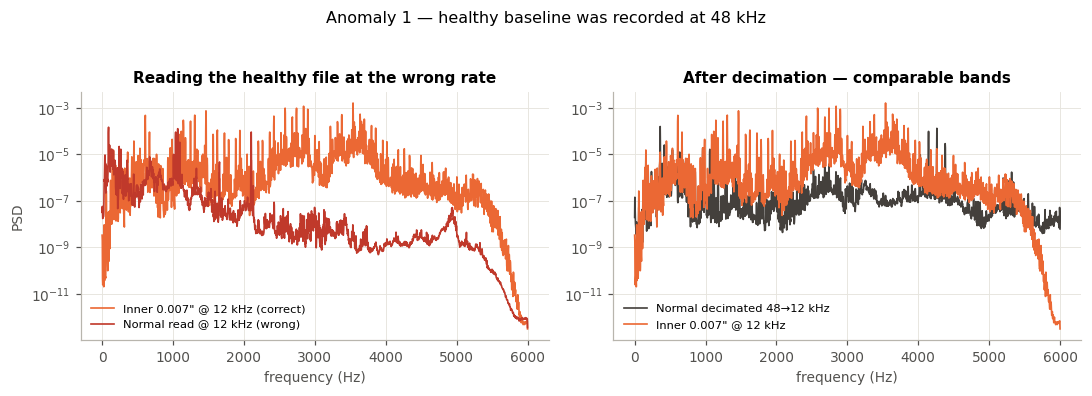

In [48]:
import scipy.io as sio
from scipy.signal import decimate, welch

files = index_files()
raw_normal = sio.loadmat(str(files[98]))["X098_DE_time"].ravel()     # healthy, 1 hp
raw_fault = sio.loadmat(str(files[106]))["X106_DE_time"].ravel()     # inner race 0.007", 1 hp

print(f"{'file':<26}{'samples':>9}{'@12kHz':>10}{'@48kHz':>10}")
print("-" * 55)
for nm, s in [("Normal 98 (1 hp)", raw_normal), ("Inner 0.007\" (1 hp)", raw_fault)]:
    print(f"{nm:<26}{len(s):>9,}{len(s)/12000:>9.1f}s{len(s)/48000:>9.1f}s")
print("\nEvery run on this rig is ~10 s. Only one reading of each file gives that.")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
f, P = welch(raw_fault, fs=12_000, nperseg=4096)
axes[0].semilogy(f, P, color=LOC_HUE["Inner"], lw=1.1, label="Inner 0.007\" @ 12 kHz (correct)")
f, P = welch(raw_normal, fs=12_000, nperseg=4096)
axes[0].semilogy(f, P, color="#c0392b", lw=1.1, label="Normal read @ 12 kHz (wrong)")
axes[0].set_title("Reading the healthy file at the wrong rate")
axes[0].set_xlabel("frequency (Hz)"); axes[0].set_ylabel("PSD")
axes[0].legend(fontsize=7.5)

f, P = welch(decimate(raw_normal, 4, ftype="fir", zero_phase=True), fs=12_000, nperseg=4096)
axes[1].semilogy(f, P, color=INK, lw=1.1, label="Normal decimated 48→12 kHz")
f, P = welch(raw_fault, fs=12_000, nperseg=4096)
axes[1].semilogy(f, P, color=LOC_HUE["Inner"], lw=1.1, label="Inner 0.007\" @ 12 kHz")
axes[1].set_title("After decimation — comparable bands")
axes[1].set_xlabel("frequency (Hz)")
axes[1].legend(fontsize=7.5)
plt.suptitle("Anomaly 1 — healthy baseline was recorded at 48 kHz", y=1.04, fontsize=10.5)
plt.tight_layout(); plt.savefig("figures/i2_sampling_rate.png"); plt.show()

### 3. Investigate feature distributions, class relationships, and class imbalance

In [50]:
# -------------------------------------- missing values, duplicates, impossible values
flat = X.reshape(len(X), -1)
print("missing values (NaN):      ", int(np.isnan(flat).sum()))
print("non-finite values (inf):   ", int(np.isinf(flat).sum()))
print("duplicated raw windows:    ", int(len(flat) - len(np.unique(flat, axis=0))))
print("constant (dead) windows:   ", int((flat.std(axis=1) == 0).sum()))
print(f"acceleration range:         [{flat.min():.3f}, {flat.max():.3f}] g")
print(f"per-window RMS range:       [{flat.std(axis=1).min():.4f}, "
      f"{flat.std(axis=1).max():.4f}] g")
print("\nA healthy 2 hp machine sits at a few hundredths of a g RMS and a badly spalled")
print("bearing at a few tenths. Nothing here is outside what this rig can physically")
print("produce, so there are no impossible values to remove and nothing to impute.")

missing values (NaN):       0
non-finite values (inf):    0
duplicated raw windows:     0
constant (dead) windows:    0
acceleration range:         [-6.653, 6.653] g
per-window RMS range:       [0.0538, 0.8758] g

A healthy 2 hp machine sits at a few hundredths of a g RMS and a badly spalled
bearing at a few tenths. Nothing here is outside what this rig can physically
produce, so there are no impossible values to remove and nothing to impute.


> **The duplicate count above is not decoration: it caught a real bug.**
> On the first run it reported **59 duplicated windows**, exactly one recording's worth.
> The cause was in the file, not the code: `Normal/99_Normal_2.mat` ships a stray copy of
> the *previous* record's variables beside its own,
> `['ans', 'X098_DE_time', 'X098_FE_time', 'X099_DE_time', 'X099_FE_time']`, so selecting
> "the first key ending in `DE_time`" loads record 98, the **1 hp** baseline, in place of
> the 2 hp one. Because this study splits by motor load, that put a byte-identical copy of
> a training recording into the validation set. `read_mat` now resolves the
> channel by the file's own record number, and the count is 0. The check stays in the
> notebook so the bug cannot come back unnoticed.


### 4. Present relevant visualizations

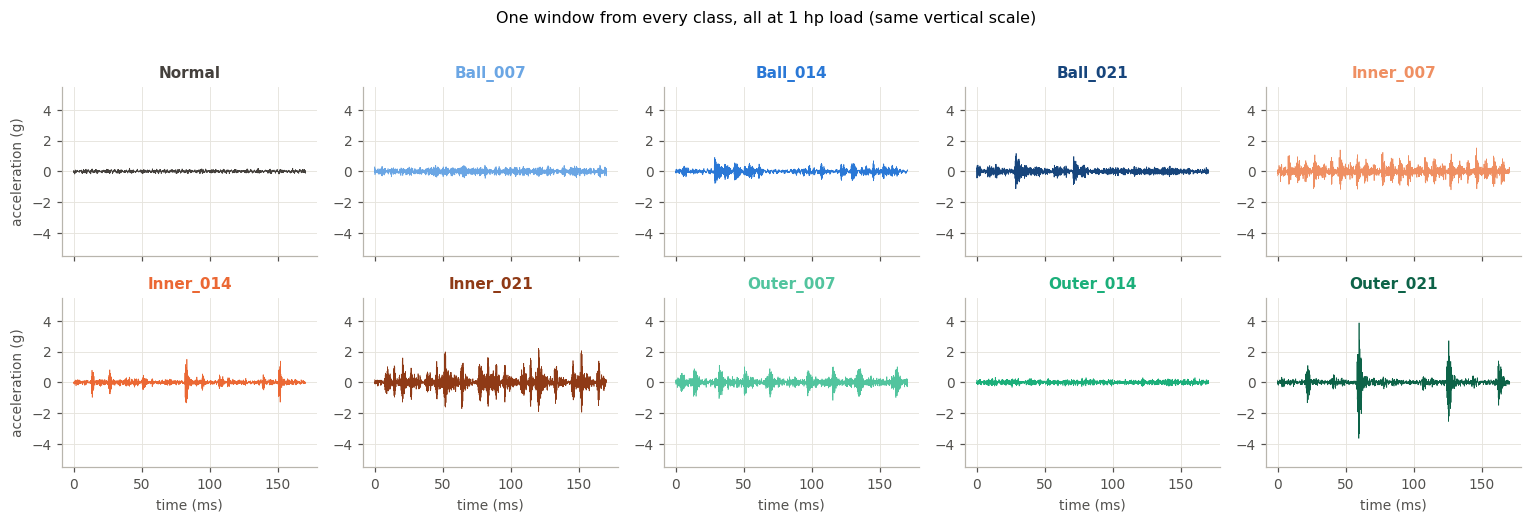

In [51]:
fig, axes = plt.subplots(2, 5, figsize=(14, 4.6), sharex=True)
t_ms = np.arange(WINDOW) / FS * 1000
for ax, cls in zip(axes.ravel(), CLASSES):
    w = X[(y == CLASSES.index(cls)) & (meta["load"] == 1)][0]
    ax.plot(t_ms, w, lw=0.45, color=class_colour(cls))
    ax.set_title(cls, color=class_colour(cls))
    ax.set_ylim(-5.5, 5.5)
for ax in axes[1]:
    ax.set_xlabel("time (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("acceleration (g)")
plt.suptitle("One window from every class, all at 1 hp load (same vertical scale)",
             y=1.02, fontsize=10.5)
plt.tight_layout(); plt.savefig("figures/i2_waveforms.png"); plt.show()

Healthy vibration is low and noise-like. The race faults produce clear periodic impacts;
the 0.021" faults are violent enough to be obvious by eye. Ball faults are the quiet ones:
a defect on a rolling element only strikes a raceway intermittently as the ball spins,
so its signature is weaker and less regular than a race fault of the same size. That
asymmetry shows up again in the errors in Task I.5.

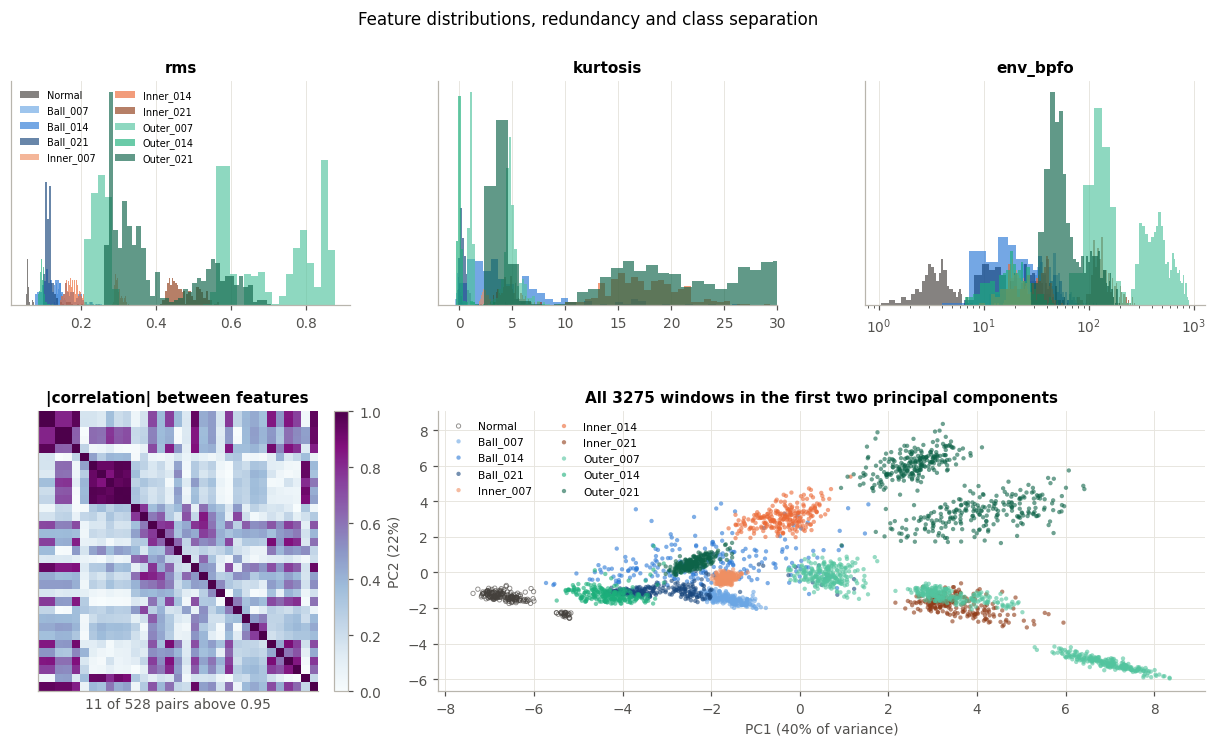

11 feature pairs correlate above 0.95: the time-domain energy measures
(rms, std, peak, mean_abs) largely restate each other.


In [90]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

fig = plt.figure(figsize=(14, 7.2))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.25], hspace=0.42, wspace=0.26)

for ax, col in zip([fig.add_subplot(gs[0, i]) for i in range(3)],
                   ["rms", "kurtosis", "env_bpfo"]):
    for cls in CLASSES:
        ax.hist(F[col][labels == cls], bins=36, alpha=0.65, label=cls,
                color=class_colour(cls))
    ax.set_title(col); ax.set_yticks([])
    if col == "kurtosis":
        ax.set_xlim(-2, 30)
    if col == "env_bpfo":
        ax.set_xscale("log")
fig.axes[0].legend(fontsize=6.4, ncol=2)

ax = fig.add_subplot(gs[1, 0])
corr = F.corr().abs().to_numpy()
im = ax.imshow(corr, cmap="BuPu", vmin=0, vmax=1)
ax.set_title("|correlation| between features"); ax.set_xticks([]); ax.set_yticks([])
plt.colorbar(im, ax=ax, fraction=0.046)
iu = np.triu_indices_from(corr, k=1)
ax.set_xlabel(f"{(corr[iu] > 0.95).sum()} of {len(iu[0])} pairs above 0.95")

Z = StandardScaler().fit_transform(Xf)
pcs = PCA(n_components=2, random_state=SEED).fit(Z)
P = pcs.transform(Z)
ax = fig.add_subplot(gs[1, 1:])
for cls in CLASSES:
    m = labels == cls
    ax.scatter(P[m, 0], P[m, 1], s=8, alpha=0.6, label=cls, color=class_colour(cls),
               edgecolors="none" if cls != "Normal" else INK,
               facecolors=class_colour(cls) if cls != "Normal" else "none", lw=0.6)
ax.set_xlabel(f"PC1 ({pcs.explained_variance_ratio_[0]*100:.0f}% of variance)")
ax.set_ylabel(f"PC2 ({pcs.explained_variance_ratio_[1]*100:.0f}%)")
ax.set_title("All 3275 windows in the first two principal components")
ax.legend(fontsize=7, ncol=2, loc="best")
plt.suptitle("Feature distributions, redundancy and class separation", y=0.97, fontsize=11)
plt.savefig("figures/i2_distributions.png"); plt.show()

print(f"{(corr[iu] > 0.95).sum()} feature pairs correlate above 0.95: the time-domain "
      f"energy measures\n(rms, std, peak, mean_abs) largely restate each other.")

**What the exploration says.** The classes separate, but not cleanly, and not all at once:
`Normal` is isolated by energy alone, the outer-race classes form a well-spread arc ordered
by severity, and the ball and inner-race groups overlap in the middle of the plane. Several
features are near-duplicates of one another. We keep them all rather than pruning: an SVM
with an L2 penalty tolerates correlated inputs, and dropping columns by correlation on the
full dataset would use information from the test load, which is exactly the leak Task I.3
is about.

### 5. Feature engineering

Three families, all computed identically for every window regardless of its label.

**Time domain.** The standard condition-monitoring statistics. RMS tracks overall energy;
kurtosis and crest factor measure *impulsiveness*, which is what distinguishes a spalled
bearing from a merely unbalanced one.

**Frequency domain.** Band energies, centroid, spread and entropy of the Hann-windowed
spectrum. Damage shifts energy into the structural resonances it excites, which moves
these descriptors.

**Envelope spectrum.** This is the physics. A defect produces a repetitive impact whose
rate depends on which surface is damaged. For this bearing those rates are fixed multiples
of shaft speed: inner race **5.415×**, outer race **3.585×**, ball spin **2.357×**, cage
**0.398×**. The impacts are not loud at those frequencies directly; they *amplitude-modulate*
a high-frequency resonance. So we band-pass 1–5 kHz, take the Hilbert envelope to
demodulate, transform that, and read the height of the peaks at each defect rate and its
first three harmonics. Shaft speed differs with load, so the frequencies are recomputed
per window from that recording's measured rpm.

In [52]:
from scipy.signal import butter, hilbert, sosfiltfilt
from scipy.stats import kurtosis, skew

_SOS = butter(4, [1000, 5000], btype="bandpass", fs=FS, output="sos")
_HANN = np.hanning(WINDOW)
_EPS = 1e-12


def time_features(Xw):
    absX = np.abs(Xw)
    rms = np.sqrt(np.mean(Xw ** 2, axis=1))
    peak = absX.max(axis=1)
    mean_abs = absX.mean(axis=1)
    sqrt_mean = np.mean(np.sqrt(absX), axis=1) ** 2
    return pd.DataFrame({
        "rms": rms, "std": Xw.std(axis=1), "peak": peak,
        "peak_to_peak": Xw.max(axis=1) - Xw.min(axis=1), "mean_abs": mean_abs,
        "skewness": skew(Xw, axis=1), "kurtosis": kurtosis(Xw, axis=1),
        "crest_factor": peak / (rms + _EPS),
        "shape_factor": rms / (mean_abs + _EPS),
        "impulse_factor": peak / (mean_abs + _EPS),
        "clearance_factor": peak / (sqrt_mean + _EPS),
        "zero_cross_rate": np.mean(np.diff(np.signbit(Xw), axis=1), axis=1),
    })


def spectral_features(Xw, n_bands=8):
    spec = np.abs(np.fft.rfft(Xw * _HANN, axis=1))
    freq = np.fft.rfftfreq(Xw.shape[1], 1 / FS)
    power = spec ** 2
    total = power.sum(axis=1) + _EPS
    pn = power / total[:, None]
    centroid = (pn * freq).sum(axis=1)
    spread = np.sqrt((pn * (freq - centroid[:, None]) ** 2).sum(axis=1))
    out = pd.DataFrame({
        "spec_centroid": centroid, "spec_spread": spread,
        "spec_skew": (pn * (freq - centroid[:, None]) ** 3).sum(axis=1) / (spread ** 3 + _EPS),
        "spec_kurtosis": (pn * (freq - centroid[:, None]) ** 4).sum(axis=1) / (spread ** 4 + _EPS),
        "spec_entropy": -(pn * np.log(pn + _EPS)).sum(axis=1),
        "dominant_freq": freq[power.argmax(axis=1)],
        "total_power_log": np.log10(total),
    })
    edges = np.linspace(0, FS / 2, n_bands + 1)
    for i in range(n_bands):
        m = (freq >= edges[i]) & (freq < edges[i + 1])
        out[f"band_{int(edges[i])}_{int(edges[i+1])}Hz"] = pn[:, m].sum(axis=1)
    return out


def envelope_features(Xw, shaft_hz, n_harm=3, tol_hz=3.0):
    """Peak height at each bearing defect rate in the envelope spectrum."""
    band = sosfiltfilt(_SOS, Xw, axis=1)
    env = np.abs(hilbert(band, axis=1))
    env = env - env.mean(axis=1, keepdims=True)
    espec = np.abs(np.fft.rfft(env * _HANN, axis=1))
    efreq = np.fft.rfftfreq(Xw.shape[1], 1 / FS)
    baseline = np.median(espec, axis=1) + _EPS
    out = {}
    for name, mult in [("bpfo", BPFO_MULT), ("bpfi", BPFI_MULT),
                       ("bsf", BSF_MULT), ("ftf", FTF_MULT)]:
        acc = np.zeros(len(Xw))
        for h in range(1, n_harm + 1):
            f0 = mult * shaft_hz * h
            mask = ((efreq[None, :] >= (f0 - tol_hz)[:, None]) &
                    (efreq[None, :] <= (f0 + tol_hz)[:, None]))
            acc += np.where(mask, espec, 0).max(axis=1)
        out[f"env_{name}"] = acc / (n_harm * baseline)
    out["env_kurtosis"] = kurtosis(env, axis=1)
    out["env_rms"] = np.sqrt(np.mean(env ** 2, axis=1))
    return pd.DataFrame(out)


def extract_features(Xw, shaft_hz):
    return pd.concat([time_features(Xw), spectral_features(Xw),
                      envelope_features(Xw, shaft_hz)], axis=1)


t0 = time.time()
F = extract_features(X, meta["shaft_hz"])
feat_names = list(F.columns)
Xf = F.to_numpy(dtype=np.float64)
print(f"{F.shape[1]} features for {F.shape[0]} windows in {time.time()-t0:.1f}s")
print("NaN:", int(F.isna().sum().sum()), " inf:", int(np.isinf(Xf).sum()),
      " constant columns:", [c for c in F if F[c].var() == 0],
      " duplicated feature rows:", int(F.duplicated().sum()))

33 features for 3275 windows in 2.6s
NaN: 0  inf: 0  constant columns: []  duplicated feature rows: 0


#### Does the physics show up in the features?

If the envelope features work, each race fault should light up its *own* defect frequency
and nobody else's. This is the single most important diagnostic figure in the notebook:
it says whether the features mean anything or whether the model is about to learn noise.

Mean envelope-spectrum peak height at each defect frequency

           BPFO (outer, 3.585x)  BPFI (inner, 5.415x)  BSF (ball, 2.357x)
class                                                                    
Normal                      4.0                   3.3                 4.0
Ball_007                   39.5                  35.1                40.0
Ball_014                   31.3                  23.6                42.2
Ball_021                   26.9                  28.7                24.2
Inner_007                  21.5                  46.6                 6.6
Inner_014                  31.5                  47.6                41.9
Inner_021                 147.4                 351.0               129.0
Outer_007                 382.9                 101.0               149.3
Outer_014                  22.3                  23.0                18.6
Outer_021                  79.2                  25.3                64.7


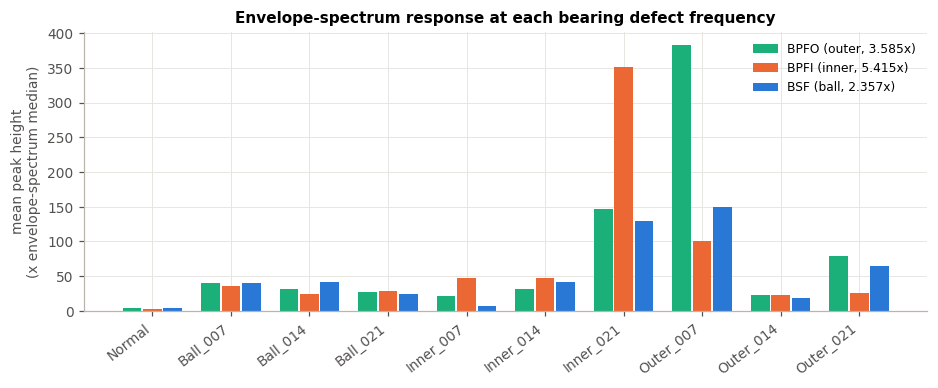

In [53]:
labels = np.array([CLASSES[i] for i in y])
loc = meta["location"]
env_tab = (pd.DataFrame({"class": labels,
                         "BPFO (outer, 3.585x)": F["env_bpfo"],
                         "BPFI (inner, 5.415x)": F["env_bpfi"],
                         "BSF (ball, 2.357x)": F["env_bsf"]})
           .groupby("class").mean().reindex(CLASSES))
print("Mean envelope-spectrum peak height at each defect frequency\n")
print(env_tab.round(1).to_string())

fig, ax = plt.subplots(figsize=(8.6, 3.6))
xpos = np.arange(len(CLASSES))
w = 0.26
for k, (col, hue) in enumerate(zip(env_tab.columns,
                                   [LOC_HUE["Outer"], LOC_HUE["Inner"], LOC_HUE["Ball"]])):
    ax.bar(xpos + (k - 1) * w, env_tab[col], w * 0.92, label=col, color=hue)
ax.set_xticks(xpos); ax.set_xticklabels(CLASSES, rotation=38, ha="right")
ax.set_ylabel("mean peak height\n(x envelope-spectrum median)")
ax.set_title("Envelope-spectrum response at each bearing defect frequency")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/i2_envelope.png"); plt.show()

It works where the fault is severe, and where it fails it fails informatively.

**It works.** `Outer_007` is dominated by BPFO (383 against 101 at BPFI) and `Inner_021`
by BPFI (351 against 147): each race fault excites its own defect rate, exactly as the
bearing geometry predicts, and `Normal` sits at 3–4 on all three, i.e. no peak at all.

**The ball faults never light up BSF.** `Ball_007` responds about equally at all three
rates (40 / 35 / 40). This is a real property of rolling-element defects, not a bug: a
spall on a ball strikes the inner and outer raceways alternately as the cage carries it
round, and the ball slips rather than rolls cleanly, so the energy smears across the
race-passing rates instead of concentrating at BSF.

**Two records are much quieter than their siblings.** `Outer_014` peaks at 22 where
`Outer_007` reaches 383, and `Inner_014` reaches 48 where `Inner_021` reaches 351. Both
0.014" race faults are far weaker than the 0.007" and 0.021" faults on either side of
them, which should not happen if the signal grew with defect size. That is examined next.

Three things are visible, and all three shape the results later.

**1. Both 0.014" race faults are anomalously quiet.** `Inner_014` sits at 0.18 g RMS
between `Inner_007` at 0.30 and `Inner_021` at 0.48, *below* the smaller defect.
`Outer_014` is worse: 0.10 g against 0.56 for `Outer_007`, quieter than any fault on the
rig and only 1.7× the healthy bearing. Both also carry a kurtosis signature that does not
match their neighbours (`Inner_014` ≈ 17.6 against 2.4 and 4.8). The pattern is a narrow,
sharp defect that strikes hard but transmits little average energy, where the 0.021" faults
are wide enough to excite the structure continuously. Whether that is the geometry of those
particular seeded notches or something about how those runs were made, it cannot be read
off the files, so it is reported as measured.

**2. `Inner_014` lands in ball-fault territory.** Its 0.18 g RMS is nearest the ball
classes at 0.12–0.14 g, and its envelope response at BPFI (48) is far below `Inner_021`'s
(351). An energy-driven classifier has every reason to call it a ball fault, and in
Task I.5 that is precisely what happens.

**3. Ball severity is almost flat.** The three ball classes span 0.12–0.14 g RMS, a 15%
spread against the 5× spread across inner-race severities. Grading how bad a ball fault is
from this signal has very little to work with, which is a limitation of the measurement
rather than of any model fitted to it.

### Scaling, and why an SVM cannot work without it

*A note on the test load before the sections that follow.* The 3 hp load never selects a
feature, a kernel or a hyperparameter anywhere in this notebook: every choice is made on the
training and validation loads. A few sections print a test-load score, only to show what a
practice costs, and none of those numbers feeds a decision.

An SVM measures distances between points, so a column measured in tens drowns out a column
measured in thousandths. The spread of our 33 features is the first thing to look at.

In [91]:
spread = F.std().sort_values(ascending=False)
print("spread (standard deviation) of the bearing features\n")
print(pd.concat([spread.head(5), spread.tail(5)]).to_frame("std").round(5).to_string())
print(f"\nlargest : smallest = {spread.max() / spread.min():,.0f} : 1")

spread (standard deviation) of the bearing features

                         std
dominant_freq     1152.97144
spec_centroid      388.68791
spec_spread        361.22222
env_bpfo           174.78056
env_bpfi            91.03395
zero_cross_rate      0.05971
band_750_1500Hz      0.05267
band_4500_5250Hz     0.00936
band_1500_2250Hz     0.00782
band_5250_6000Hz     0.00492

largest : smallest = 234,421 : 1


Now the same SVM with the same settings (`kernel="rbf"`, `C=1.0`, `gamma="scale"`, the
scikit-learn defaults), where only the scaling changes.

In [92]:
from sklearn.preprocessing import MinMaxScaler

scal_rows = []
for name, scaler in [("no scaling", None),
                     ("StandardScaler", StandardScaler()),
                     ("MinMaxScaler", MinMaxScaler())]:
    steps = ([("sc", scaler)] if scaler is not None else []) + \
            [("svm", SVC(kernel="rbf", C=1.0, gamma="scale",
                         class_weight="balanced", random_state=SEED))]
    t0 = time.time()
    m = Pipeline(steps).fit(Xtr, ytr)
    p = m.predict(Xte)
    scal_rows.append(dict(scaling=name, accuracy=(p == yte).mean(),
                     macro_F1=f1_score(yte, p, average="macro"),
                     distinct_classes_predicted=len(np.unique(p)),
                     fit_s=round(time.time() - t0, 2)))
print("Same SVM, same settings, only the scaling changes\n")
print(pd.DataFrame(scal_rows).round(4).to_string(index=False))

Same SVM, same settings, only the scaling changes

       scaling  accuracy  macro_F1  distinct_classes_predicted  fit_s
    no scaling    0.5586    0.5153                          10   0.61
StandardScaler    0.8634    0.7673                          10   0.19
  MinMaxScaler    0.8549    0.7510                          10   0.07


The scaler must be fitted on the training windows only. `fit` computes the mean and standard
deviation of whatever it is shown, so if it sees the test set those numbers carry information
the model is not allowed to have. Here is what breaking that rule costs, measured.

In [93]:
right = Pipeline([("sc", StandardScaler()),
                  ("svm", SVC(kernel="rbf", C=1, gamma=0.01, class_weight="balanced",
                              random_state=SEED))]).fit(Xtr, ytr)
f1_right = f1_score(yte, right.predict(Xte), average="macro")

sc_all = StandardScaler().fit(Xf)                     # <-- the mistake: fitted on everything
wrong = SVC(kernel="rbf", C=1, gamma=0.01, class_weight="balanced",
            random_state=SEED).fit(sc_all.transform(Xtr), ytr)
f1_wrong = f1_score(yte, wrong.predict(sc_all.transform(Xte)), average="macro")

print(f"scaler fitted on the training windows only : macro-F1 {f1_right:.4f}   (correct)")
print(f"scaler fitted on all windows               : macro-F1 {f1_wrong:.4f}   (leaks)")
print(f"\ndifference {f1_wrong - f1_right:+.4f}")

# how different are the two scalers, actually?
s_tr, s_all = StandardScaler().fit(Xtr), StandardScaler().fit(Xf)
cmp_sc = pd.DataFrame({"std_train": s_tr.scale_, "std_all": s_all.scale_},
                      index=feat_names)
cmp_sc["ratio"] = cmp_sc.std_all / cmp_sc.std_train
cmp_sc["mean_shift_in_train_sd"] = (s_all.mean_ - s_tr.mean_) / s_tr.scale_
print("\nhow different are the two scalers?")
print(cmp_sc.reindex(cmp_sc.ratio.sub(1).abs().sort_values(ascending=False).index)
      .head(4).round(3).to_string())
print(f"\nmedian |ratio - 1| across the 33 features : "
      f"{(cmp_sc.ratio - 1).abs().median():.3f}")
print(f"median |mean shift|                       : "
      f"{cmp_sc.mean_shift_in_train_sd.abs().median():.3f} training sd")

scaler fitted on the training windows only : macro-F1 0.8454   (correct)
scaler fitted on all windows               : macro-F1 0.9646   (leaks)

difference +0.1191

how different are the two scalers?
                  std_train  std_all  ratio  mean_shift_in_train_sd
band_750_1500Hz       0.039    0.053  1.350                   0.343
band_4500_5250Hz      0.008    0.009  1.195                   0.144
band_3750_4500Hz      0.103    0.089  0.863                  -0.043
band_5250_6000Hz      0.005    0.005  0.911                  -0.010

median |ratio - 1| across the 33 features : 0.020
median |mean shift|                       : 0.024 training sd


**Fitting the scaler on the full dataset increases Macro-F1 by 0.12**, almost as much as the 0.15 gain from window-shuffling leakage in Task I.3. However, the scalers are very similar, except for `band_750_1500Hz`, whose scale changes by 35%.

This suggests that **the model is sensitive to small changes in preprocessing rather than gaining much extra information**. The RBF SVM is affected by changes in feature scaling, which can alter its predictions.

Two lessons follow: keep the scaler inside the `Pipeline` to prevent data leakage, and avoid reporting Macro-F1 to three decimal places because the model is not stable enough. This also agrees with Part II, where different CNN runs showed large performance variations.

### How alike are neighbouring windows? A semivariogram

Tobler's first law: **"everything is related to everything else, but near things are more
related than distant things."** Geostatistics turns it into the semivariogram,

$$\gamma(h) \;=\; \frac{1}{2N(h)} \sum_{(i,j)\in N(h)} \bigl(z_i - z_j\bigr)^2$$

and reads three numbers off it: the **nugget** (scatter at zero separation), the **sill**
(the variance it levels off at) and the **range** (the separation beyond which two
measurements stop being related).

The usual setting is distance in space. Our windows are separated in **time** along a
recording, and the same arithmetic applies. This turns the central claim of this task and of
Part II, that neighbouring windows are near-duplicates and must not be split at random, from
an assertion into a measurement.

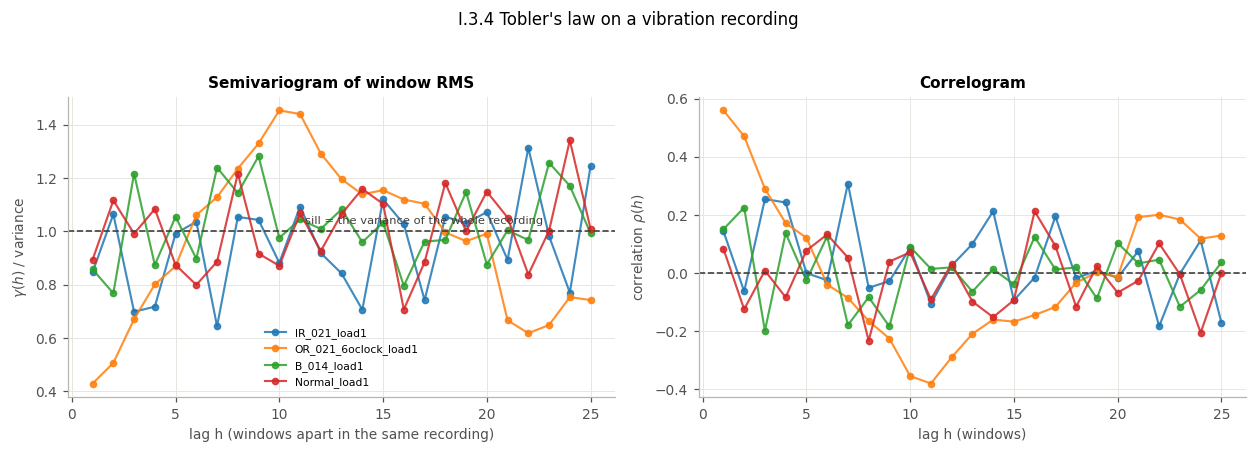

In [94]:
def semivariogram(values, max_lag):
    """gamma(h) over integer lags h, for values indexed by position along a recording."""
    out = []
    for h in range(1, max_lag + 1):
        d = values[h:] - values[:-h]
        out.append((h, 0.5 * np.mean(d ** 2), len(d)))
    return pd.DataFrame(out, columns=["lag", "gamma", "n_pairs"])


def correlogram(values, max_lag):
    v = values - values.mean()
    denom = np.sum(v * v)
    return pd.DataFrame([(h, float(np.sum(v[h:] * v[:-h]) / denom))
                         for h in range(1, max_lag + 1)], columns=["lag", "rho"])


# one recording at a time, so "lag" always means windows apart in the same signal
MAXLAG = 25
recs_used = ["IR_021_load1", "OR_021_6oclock_load1", "B_014_load1", "Normal_load1"]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
store = {}
for rname in recs_used:
    m = meta["rec_id"] == rname
    v = F.loc[m, "rms"].to_numpy()
    g = semivariogram(v, min(MAXLAG, len(v) - 2))
    c = correlogram(v, min(MAXLAG, len(v) - 2))
    store[rname] = (g, c, v)
    axes[0].plot(g.lag, g.gamma / v.var(), "o-", ms=4, lw=1.4, label=rname, alpha=.85)
    axes[1].plot(c.lag, c.rho, "o-", ms=4, lw=1.4, label=rname, alpha=.85)

axes[0].axhline(1.0, color=INK, ls="--", lw=1.1)
axes[0].text(MAXLAG * .45, 1.03, "sill = the variance of the whole recording",
             fontsize=7.5, color=INK)
axes[0].set_xlabel("lag h (windows apart in the same recording)")
axes[0].set_ylabel(r"$\gamma(h)$ / variance")
axes[0].set_title("Semivariogram of window RMS")
axes[0].legend(fontsize=7)
axes[1].axhline(0, color=INK, ls="--", lw=1.1)
axes[1].set_xlabel("lag h (windows)")
axes[1].set_ylabel(r"correlation $\rho(h)$")
axes[1].set_title("Correlogram")
plt.suptitle("I.3.4 Tobler's law on a vibration recording", y=1.04)
plt.tight_layout(); plt.savefig("figures/i3_variogram.png"); plt.show()

In [95]:
print("Where does gamma(h) reach the sill? (the 'range')\n")
print(f"{'recording':<24}{'rho(1)':>9}{'rho(2)':>9}{'range':>9}{'nugget/sill':>13}")
print("-" * 66)
rng_rows = []
for rname, (g, c, v) in store.items():
    ratio = g.gamma / v.var()
    reach = g.lag[ratio >= 0.95]
    rng = int(reach.iloc[0]) if len(reach) else np.nan
    nug = float(ratio.iloc[0])
    rng_rows.append(dict(recording=rname, rho1=c.rho.iloc[0], rho2=c.rho.iloc[1],
                         range_windows=rng, nugget_over_sill=nug))
    print(f"{rname:<24}{c.rho.iloc[0]:>9.3f}{c.rho.iloc[1]:>9.3f}"
          f"{str(rng):>9}{nug:>13.3f}")
pd.DataFrame(rng_rows).to_csv("results/part1_variogram.csv", index=False)

Where does gamma(h) reach the sill? (the 'range')

recording                  rho(1)   rho(2)    range  nugget/sill
------------------------------------------------------------------
IR_021_load1                0.144   -0.064        2        0.847
OR_021_6oclock_load1        0.559    0.470        6        0.430
B_014_load1                 0.150    0.225        3        0.857
Normal_load1                0.083   -0.125        2        0.893


### What the Variogram Shows

**Three recordings (IR_021, B_014 and Normal) show low spatial dependence.** Their neighbouring windows are already quite different, meaning the 2048-sample window size is suitable and consecutive windows are not simply copies.

**OR_021 at 6 o'clock is different.** It has a high correlation of 0.56 at lag 1 and a range of six windows (about one second). This suggests that neighbouring windows share similar information, possibly because the defect signal changes slowly as the bearing rotates.

**This shows why random splitting can be misleading.** Some recordings contain similar neighbouring windows, allowing the model to recognise recording-specific patterns. Splitting data by recording helps prevent this problem and gives a more reliable evaluation.

**The first few lags are the most reliable.** Values after lag 10 are less reliable because there are fewer window pairs available.

**Overlapping windows would increase data leakage.** With 50% overlap, neighbouring windows share 1024 samples, making them highly similar. This is why the project uses non-overlapping windows.



**Preprocessing applied, and why.**

| Step | Decision | Reason |
|---|---|---|
| Resampling | healthy 48 kHz → 12 kHz, FIR anti-alias | otherwise the healthy class is identifiable by sampling rate |
| Windowing | 2048 samples, **non-overlapping** | overlapping windows share samples and leak across a split |
| Imputation | none | no missing values exist |
| Outlier removal | none | `Inner_014` is a real measurement, not an error; removing it would hide the hardest case |
| Scaling | `StandardScaler`, **fitted on training data only** | RBF and linear SVMs are distance-based; `env_bpfo` spans 0–400 while `skewness` spans ±1 |
| Class weights | `class_weight="balanced"` | 3.4 : 1 imbalance |

<a id="task-i3"></a>
---
## Task I.3 — Classification Strategy and Baseline

**Splits** Training: 0 and 1 hp. Validation: 2 hp. Test: 3 hp. Each recording was made at one load, so splitting by load keeps whole recordings together. The test load is used only once, at the end. This checks whether the model works at a load it has never seen.

**Leakage**

- Neighbouring windows from one recording are near-copies. A random window split therefore leaks. For the same model, macro-F1 is 0.994 with a random split and 0.845 with the load split. The 0.15 difference is leakage.

- The same physical bearing appears at every load, so some leakage remains that the split cannot remove. We report this as a limitation.

- The scaler is fitted on training data only, inside the pipeline.

- Hyperparameters and class weights are chosen on validation data, never on the test load.

**Primary metric: macro-averaged F1** Accuracy is misleading: always predicting the largest class gives 21% accuracy. Macro-F1 weights every class equally, so missing a rare fault class counts as much as missing a common one.

In [58]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

tr, va, te = make_split(meta)
Xtr, ytr = Xf[tr], y[tr]
Xva, yva = Xf[va], y[va]
Xte, yte = Xf[te], y[te]

split_tab = pd.DataFrame({
    "train (0+1 hp)": np.bincount(ytr, minlength=10),
    "val (2 hp)": np.bincount(yva, minlength=10),
    "test (3 hp)": np.bincount(yte, minlength=10)}, index=CLASSES)
split_tab.loc["TOTAL"] = split_tab.sum()
print(split_tab.to_string())
print("\nrecordings shared between train and test:",
      len(set(meta['rec_id'][tr]) & set(meta['rec_id'][te])))

           train (0+1 hp)  val (2 hp)  test (3 hp)
Normal                 88          59           59
Ball_007              118          59           59
Ball_014              118          59           59
Ball_021              118          59           59
Inner_007             118          59           60
Inner_014             118          59           59
Inner_021             118          59           59
Outer_007             354         177          177
Outer_014             118          59           59
Outer_021             354         177          177
TOTAL                1622         826          827

recordings shared between train and test: 0


In [59]:
# -------------------------------------------------- the leak, measured
idx = np.arange(len(y))
i_tr, i_te = train_test_split(idx, test_size=0.25, random_state=SEED, stratify=y)
shared = sum(meta["rec_id"][i] in set(meta["rec_id"][i_tr]) for i in i_te)

leaky = Pipeline([("sc", StandardScaler()),
                  ("svm", SVC(kernel="rbf", C=1, gamma=0.01,
                              class_weight="balanced", random_state=SEED))])
leaky.fit(Xf[i_tr], y[i_tr])
f1_leaky = f1_score(y[i_te], leaky.predict(Xf[i_te]), average="macro")

honest = Pipeline([("sc", StandardScaler()),
                   ("svm", SVC(kernel="rbf", C=1, gamma=0.01,
                               class_weight="balanced", random_state=SEED))])
honest.fit(Xtr, ytr)
f1_honest = f1_score(yte, honest.predict(Xte), average="macro")

print(f"random 75/25 window split    macro-F1 = {f1_leaky:.4f}")
print(f"   {shared}/{len(i_te)} test windows ({100*shared/len(i_te):.0f}%) came from a "
      f"recording also used in training")
print(f"held-out-load split          macro-F1 = {f1_honest:.4f}")
print(f"\nThe same model, the same features. The {f1_leaky-f1_honest:.2f} difference is "
      f"entirely the split.")

print("\n--- baselines on the held-out load ---")
for nm, d in [("always the largest class", DummyClassifier(strategy="most_frequent")),
              ("guess from class priors",
               DummyClassifier(strategy="stratified", random_state=SEED))]:
    p = d.fit(Xtr, ytr).predict(Xte)
    print(f"{nm:<26} accuracy {(p==yte).mean():.3f}   macro-F1 "
          f"{f1_score(yte, p, average='macro'):.3f}")

random 75/25 window split    macro-F1 = 0.9937
   819/819 test windows (100%) came from a recording also used in training
held-out-load split          macro-F1 = 0.8454

The same model, the same features. The 0.15 difference is entirely the split.

--- baselines on the held-out load ---
always the largest class   accuracy 0.214   macro-F1 0.035
guess from class priors    accuracy 0.134   macro-F1 0.106


<a id="task-i4"></a>
---
## Task I.4 — SVM Modeling

**1. Model and tuning.** Linear and RBF SVMs (polynomial is also used but it is optional), each in a pipeline with a StandardScaler. Hyperparameters were selected with leave-one-load-out cross-validation over the training and validation loads (three folds). The 2 hp load alone could not separate the settings, because all kernels reached 1.000 on it.

In [69]:
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, PredefinedSplit

Xdev = np.vstack([Xtr, Xva])
ydev = np.concatenate([ytr, yva])
gdev = np.concatenate([meta["load"][tr], meta["load"][va]])
# one fold: fit on the training loads, score on the validation load. Test is untouched.
ps = PredefinedSplit(np.concatenate([np.full(len(ytr), -1), np.zeros(len(yva))]))

GRIDS = {
    "linear": ({"svm__C": [0.01, 0.1, 1, 10, 100, 1000]},
               dict(kernel="linear")),
    "rbf": ({"svm__C": [0.1, 1, 10, 100, 1000],
             "svm__gamma": ["scale", 1e-4, 1e-3, 1e-2, 1e-1, 1]},
            dict(kernel="rbf")),
    "poly (d=3)": ({"svm__C": [0.1, 1, 10, 100],
                    "svm__gamma": ["scale", 1e-3, 1e-2, 1e-1]},
                   dict(kernel="poly", degree=3)),
}


def make_svm(**kw):
    return Pipeline([("sc", StandardScaler()),
                     ("svm", SVC(class_weight="balanced", random_state=SEED, **kw))])


# ---- first, the obvious procedure: tune on the single validation load ------
val_rows = []
for name, (grid, kw) in GRIDS.items():
    gs = GridSearchCV(make_svm(**kw), grid, cv=ps, scoring="f1_macro",
                      n_jobs=-1, refit=False).fit(Xdev, ydev)
    val_rows.append(dict(kernel=name, best_val_macroF1=gs.best_score_,
                         settings_tried=len(gs.cv_results_["params"]),
                         settings_tied_at_best=int(
                             (gs.cv_results_["mean_test_score"] >= gs.best_score_ - 1e-9).sum())))
print("Tuning on the single validation load (2 hp)\n")
print(pd.DataFrame(val_rows).to_string(index=False))

Tuning on the single validation load (2 hp)

    kernel  best_val_macroF1  settings_tried  settings_tied_at_best
    linear               1.0               6                      6
       rbf               1.0              30                     14
poly (d=3)               1.0              16                      4


**A single validation load cannot separate anything.** Every kernel reaches macro-F1
= 1.000 and many settings inside each grid tie at that value, so the "best" setting would
be decided by the order of the grid rather than by evidence. The 2 hp load simply sits
between the two training loads and is too easy to be informative.

We therefore select with **leave-one-load-out cross-validation over the three development
loads** instead: three folds, each fitting on two loads and scoring the third, so every
fold is a genuine extrapolation to an unseen operating point. This uses the training and
validation loads only; the 3 hp test load plays no part in selecting anything.

In [70]:
logo = LeaveOneGroupOut()
search, rows = {}, []
for name, (grid, kw) in GRIDS.items():
    t0 = time.time()
    gs = GridSearchCV(make_svm(**kw), grid, cv=logo, scoring="f1_macro", n_jobs=-1,
                      refit=False, return_train_score=True).fit(Xdev, ydev, groups=gdev)
    search[name] = gs
    i = gs.best_index_
    best = {k.split("__")[1]: v for k, v in gs.best_params_.items()}
    rows.append(dict(kernel=name, **best,
                     cv_macroF1=gs.best_score_,
                     cv_std=gs.cv_results_["std_test_score"][i],
                     train_macroF1=gs.cv_results_["mean_train_score"][i],
                     secs=round(time.time() - t0, 1)))
cv_tab = pd.DataFrame(rows)
print("Leave-one-load-out CV over loads 0/1/2 — the selection procedure\n")
print(cv_tab.round(4).to_string(index=False))

best_kernel = cv_tab.loc[cv_tab["cv_macroF1"].idxmax(), "kernel"]
print(f"\nselected kernel: {best_kernel}")
print("\nper-fold scores at the selected settings:")
for r in rows:
    kw = {**GRIDS[r["kernel"]][1],
          **{k: r[k] for k in ("C", "gamma") if k in r and pd.notna(r.get(k))}}
    folds = [f1_score(ydev[b], make_svm(**kw).fit(Xdev[a], ydev[a]).predict(Xdev[b]),
                      average="macro")
             for a, b in logo.split(Xdev, ydev, groups=gdev)]
    print(f"  {r['kernel']:<12} held-out 0hp {folds[0]:.4f} | 1hp {folds[1]:.4f} | "
          f"2hp {folds[2]:.4f}   mean {np.mean(folds):.4f} (+/-{np.std(folds):.4f})")

Leave-one-load-out CV over loads 0/1/2 — the selection procedure

    kernel    C  cv_macroF1  cv_std  train_macroF1  secs  gamma
    linear  0.1      0.9878  0.0164         0.9996   0.2    NaN
       rbf  1.0      0.9887  0.0107         0.9968   4.4   0.01
poly (d=3) 10.0      0.9741  0.0355         1.0000   1.3   0.10

selected kernel: rbf

per-fold scores at the selected settings:
  linear       held-out 0hp 0.9647 | 1hp 0.9989 | 2hp 1.0000   mean 0.9878 (+/-0.0164)
  rbf          held-out 0hp 0.9744 | 1hp 0.9918 | 2hp 1.0000   mean 0.9887 (+/-0.0107)
  poly (d=3)   held-out 0hp 0.9239 | 1hp 0.9983 | 2hp 1.0000   mean 0.9741 (+/-0.0355)


### 2. Effect of the hyperparameters / 4. Analyze training and validation results for underfitting or overfitting

`gamma` sets how far a single support vector's influence reaches; `C` sets how much
training error is tolerated in exchange for a wider margin. The sweep below is the
clearest picture of under- and overfitting in this notebook.

**Under- and overfitting (RBF, γ sweep at C = 1):**

- At γ = 1e-5 the model underfits: every training point becomes a support vector and both scores fall to about 0.01.

- Between 1e-3 and 1e-1, training and validation F1 are close, and the number of support vectors falls from 1188 to 287.

- At γ = 1 the training F1 is 1.000 but validation falls to 0.707. At γ = 10, nearly every training point is a support vector. The model memorises the training data.

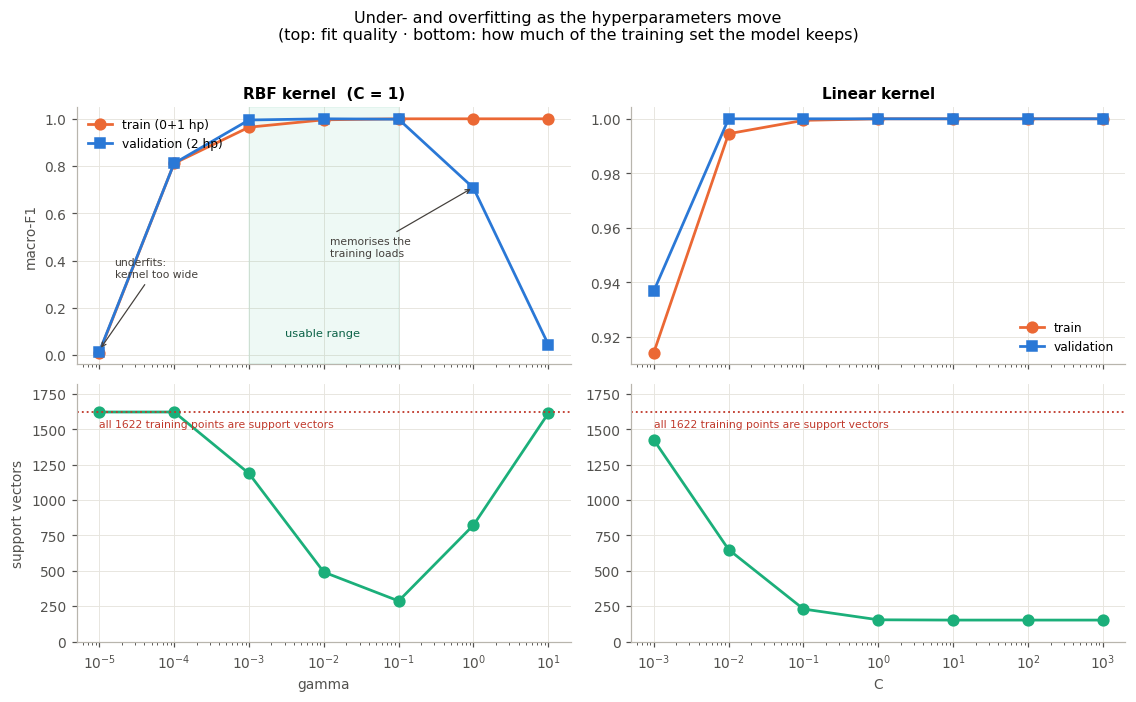

   gamma  train_F1  val_F1  support_vectors
 0.00001     0.010   0.013             1622
 0.00010     0.811   0.812             1622
 0.00100     0.964   0.995             1188
 0.01000     0.996   1.000              491
 0.10000     1.000   0.998              287
 1.00000     1.000   0.707              823
10.00000     1.000   0.044             1613


In [71]:
C_rbf = [r for r in rows if r["kernel"] == "rbf"][0]["C"]
gam_grid = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10]
gs_tr, gs_va, gs_sv = [], [], []
for g in gam_grid:
    m = make_svm(kernel="rbf", C=C_rbf, gamma=g).fit(Xtr, ytr)
    gs_tr.append(f1_score(ytr, m.predict(Xtr), average="macro"))
    gs_va.append(f1_score(yva, m.predict(Xva), average="macro"))
    gs_sv.append(int(m["svm"].n_support_.sum()))

C_grid = [1e-3, 1e-2, 1e-1, 1, 10, 100, 1000]
cs_tr, cs_va, cs_sv = [], [], []
for c in C_grid:
    m = make_svm(kernel="linear", C=c).fit(Xtr, ytr)
    cs_tr.append(f1_score(ytr, m.predict(Xtr), average="macro"))
    cs_va.append(f1_score(yva, m.predict(Xva), average="macro"))
    cs_sv.append(int(m["svm"].n_support_.sum()))

# gamma and C are different quantities, so they get their own columns rather than
# being stacked onto one shared axis.
fig, axes = plt.subplots(2, 2, figsize=(10.4, 6.2), sharex="col")

ax = axes[0, 0]
ax.semilogx(gam_grid, gs_tr, "o-", color=LOC_HUE["Inner"], label="train (0+1 hp)", lw=1.8, ms=7)
ax.semilogx(gam_grid, gs_va, "s-", color=LOC_HUE["Ball"], label="validation (2 hp)", lw=1.8, ms=7)
ax.set_ylabel("macro-F1"); ax.set_title(f"RBF kernel  (C = {C_rbf})"); ax.legend(fontsize=8)
ax.axvspan(1e-3, 1e-1, color="#1baf7a", alpha=0.07)
ax.text(3e-3, 0.08, "usable range", fontsize=7.5, color="#0d6348")
ax.annotate("underfits:\nkernel too wide", xy=(1e-5, 0.02), xytext=(1.6e-5, 0.33),
            fontsize=7, color=INK, arrowprops=dict(arrowstyle="->", color=INK, lw=0.8))
ax.annotate("memorises the\ntraining loads", xy=(1, 0.71), xytext=(0.012, 0.42),
            fontsize=7, color=INK, arrowprops=dict(arrowstyle="->", color=INK, lw=0.8))

ax = axes[0, 1]
ax.semilogx(C_grid, cs_tr, "o-", color=LOC_HUE["Inner"], label="train", lw=1.8, ms=7)
ax.semilogx(C_grid, cs_va, "s-", color=LOC_HUE["Ball"], label="validation", lw=1.8, ms=7)
ax.set_title("Linear kernel"); ax.legend(fontsize=8)

for ax, grid, sv, xlab in [(axes[1, 0], gam_grid, gs_sv, "gamma"),
                          (axes[1, 1], C_grid, cs_sv, "C")]:
    ax.semilogx(grid, sv, "o-", color=LOC_HUE["Outer"], lw=1.8, ms=7)
    ax.axhline(len(ytr), color="#c0392b", ls=":", lw=1.2)
    ax.text(grid[0], len(ytr) * 0.97, f"all {len(ytr)} training points are support vectors",
            fontsize=7, color="#c0392b", va="top")
    ax.set_xlabel(xlab); ax.set_ylim(0, len(ytr) * 1.12)
axes[1, 0].set_ylabel("support vectors")
plt.suptitle("Under- and overfitting as the hyperparameters move\n"
             "(top: fit quality · bottom: how much of the training set the model keeps)",
             y=1.02, fontsize=10.5)
plt.tight_layout(); plt.savefig("figures/i4_hyperparameters.png"); plt.show()

print(pd.DataFrame({"gamma": gam_grid, "train_F1": np.round(gs_tr, 3),
                    "val_F1": np.round(gs_va, 3), "support_vectors": gs_sv}).to_string(index=False))

### 3. Comparison

A single validation load cannot separate anything. Every kernel reaches macro-F1
= 1.000 and many settings inside each grid tie at that value, so the "best" setting would
be decided by the order of the grid rather than by evidence. The 2 hp load simply sits
between the two training loads and is too easy to be informative.

We therefore select with **leave-one-load-out cross-validation over the three development
loads** instead: three folds, each fitting on two loads and scoring the third, so every
fold is a genuine extrapolation to an unseen operating point. This uses the training and
validation loads only; the 3 hp test load plays no part in selecting anything.

In [96]:
logo = LeaveOneGroupOut()
search, rows = {}, []
for name, (grid, kw) in GRIDS.items():
    t0 = time.time()
    gs = GridSearchCV(make_svm(**kw), grid, cv=logo, scoring="f1_macro", n_jobs=-1,
                      refit=False, return_train_score=True).fit(Xdev, ydev, groups=gdev)
    search[name] = gs
    i = gs.best_index_
    best = {k.split("__")[1]: v for k, v in gs.best_params_.items()}
    rows.append(dict(kernel=name, **best,
                     cv_macroF1=gs.best_score_,
                     cv_std=gs.cv_results_["std_test_score"][i],
                     train_macroF1=gs.cv_results_["mean_train_score"][i],
                     secs=round(time.time() - t0, 1)))
cv_tab = pd.DataFrame(rows)
print("Leave-one-load-out CV over loads 0/1/2 — the selection procedure\n")
print(cv_tab.round(4).to_string(index=False))

best_kernel = cv_tab.loc[cv_tab["cv_macroF1"].idxmax(), "kernel"]
print(f"\nselected kernel: {best_kernel}")
print("\nper-fold scores at the selected settings:")
for r in rows:
    kw = {**GRIDS[r["kernel"]][1],
          **{k: r[k] for k in ("C", "gamma") if k in r and pd.notna(r.get(k))}}
    folds = [f1_score(ydev[b], make_svm(**kw).fit(Xdev[a], ydev[a]).predict(Xdev[b]),
                      average="macro")
             for a, b in logo.split(Xdev, ydev, groups=gdev)]
    print(f"  {r['kernel']:<12} held-out 0hp {folds[0]:.4f} | 1hp {folds[1]:.4f} | "
          f"2hp {folds[2]:.4f}   mean {np.mean(folds):.4f} (+/-{np.std(folds):.4f})")

Leave-one-load-out CV over loads 0/1/2 — the selection procedure

    kernel    C  cv_macroF1  cv_std  train_macroF1  secs  gamma
    linear  0.1      0.9878  0.0164         0.9996  20.8    NaN
       rbf  1.0      0.9887  0.0107         0.9968   5.2   0.01
poly (d=3) 10.0      0.9741  0.0355         1.0000   1.5   0.10

selected kernel: rbf

per-fold scores at the selected settings:
  linear       held-out 0hp 0.9647 | 1hp 0.9989 | 2hp 1.0000   mean 0.9878 (+/-0.0164)
  rbf          held-out 0hp 0.9744 | 1hp 0.9918 | 2hp 1.0000   mean 0.9887 (+/-0.0107)
  poly (d=3)   held-out 0hp 0.9239 | 1hp 0.9983 | 2hp 1.0000   mean 0.9741 (+/-0.0355)


RBF has the highest CV score, but its lead over linear (0.9887 - 0.9878 = 0.0009) is far smaller than the fold spread, so the two are effectively tied. The polynomial kernel is weakest (0.9741) and the least stable (± 0.0355, with one fold at 0.924).

### 5. Explain how kernel choice relates to the classification problem

The sweeps above are numbers. To see what a kernel does, draw it on two features: the
envelope-spectrum peaks at the outer-race and inner-race defect frequencies, on a log scale,
because those are the two numbers a vibration analyst would actually read off a spectrum.

This is **a 2-D slice: the real model uses all 33 features**. The four classes here are the
fault *locations*, so the picture stays legible; the ten-class model is used everywhere else
in this notebook.

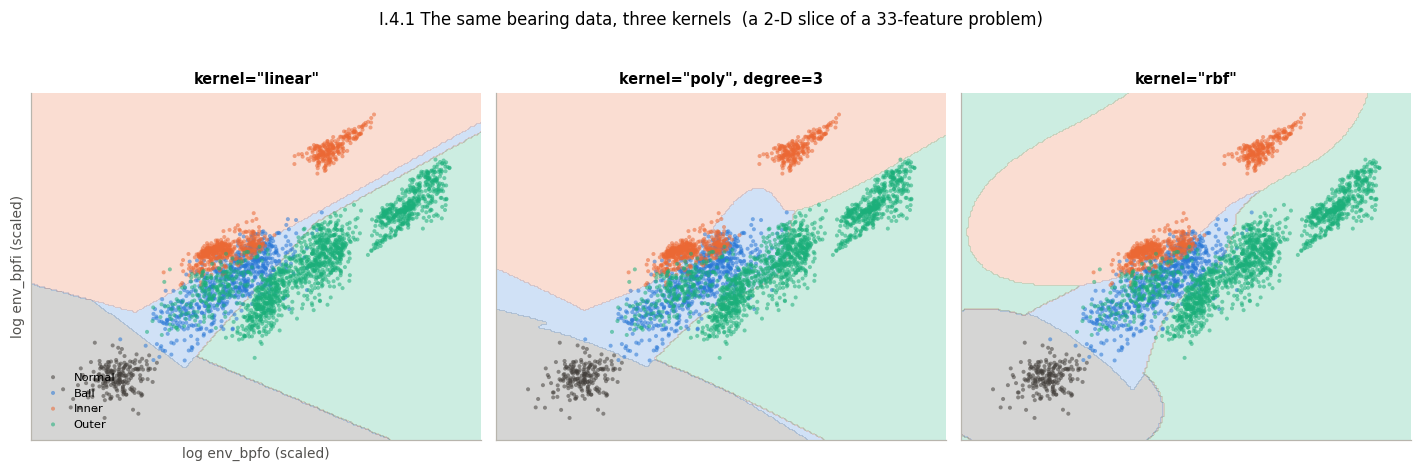

Physics check: Outer sits at high BPFO (right), Inner at high BPFI (top),
Normal low on both (bottom left), Ball in between. The axes are the two
defect frequencies, so the picture is a spectrum reading, not an abstraction.


In [72]:
PAIR = ["env_bpfo", "env_bpfi"]
V = np.log10(F[PAIR].to_numpy() + 1.0)
Vs = StandardScaler().fit_transform(V)
yloc = np.array([["Normal", "Ball", "Inner", "Outer"].index(l) for l in loc])
LOC_NAMES = ["Normal", "Ball", "Inner", "Outer"]
LOC_COLS = [LOC_HUE[n] for n in LOC_NAMES]


def boundary(ax, model, Z=None, title="", n=220):
    xx, yy = np.meshgrid(np.linspace(Vs[:, 0].min() - .4, Vs[:, 0].max() + .4, n),
                         np.linspace(Vs[:, 1].min() - .4, Vs[:, 1].max() + .4, n))
    if Z is None:
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(-.5, 4), colors=LOC_COLS, alpha=.22)
    for k, nm in enumerate(LOC_NAMES):
        m = yloc == k
        ax.scatter(Vs[m, 0], Vs[m, 1], s=7, alpha=.55, color=LOC_HUE[nm],
                   edgecolors="none", label=nm)
    ax.set_title(title, fontsize=9.5)
    ax.set_xticks([]); ax.set_yticks([])


fig, axes = plt.subplots(1, 3, figsize=(13, 4.1))
for ax, (kern, kw) in zip(axes, [("linear", {}), ("poly", {"degree": 3}), ("rbf", {})]):
    m = SVC(kernel=kern, C=1, gamma="scale", class_weight="balanced",
            random_state=SEED, **kw).fit(Vs, yloc)
    boundary(ax, m, title=f'kernel="{kern}"' + (", degree=3" if kern == "poly" else ""))
axes[0].set_xlabel("log env_bpfo (scaled)"); axes[0].set_ylabel("log env_bpfi (scaled)")
axes[0].legend(fontsize=7.5, loc="lower left")
plt.suptitle("I.4.1 The same bearing data, three kernels  (a 2-D slice of a 33-feature problem)",
             y=1.03)
plt.tight_layout(); plt.savefig("figures/i4_kernels.png"); plt.show()

print("Physics check: Outer sits at high BPFO (right), Inner at high BPFI (top),")
print("Normal low on both (bottom left), Ball in between. The axes are the two")
print("defect frequencies, so the picture is a spectrum reading, not an abstraction.")

### `C`: the price of a margin violation

A small `C` gives a wide margin and tolerates mistakes; a large `C` gives a narrow margin
that bends to catch every training point. Watch the boundary change as `C` grows, then check
the same thing on all 33 features. The held-out-load column is shown only to expose the gap
between training and test; nothing is selected from it.

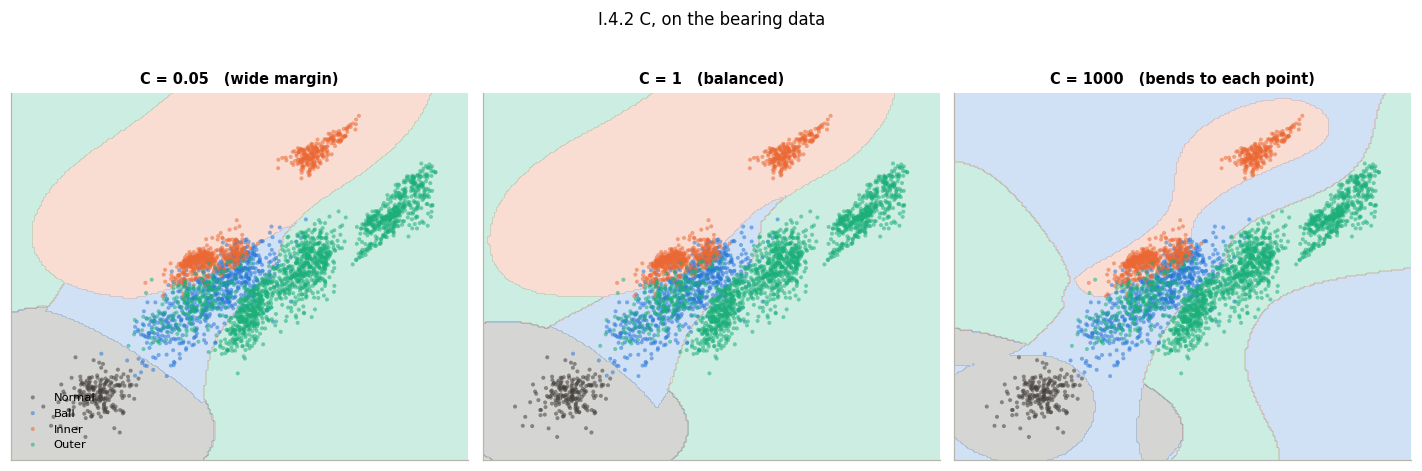

on the full 33 features, ten classes, held-out load

       C  train_F1  test_F1  support_vectors
    0.01     0.846    0.722             1622
    1.00     0.999    0.767              350
  100.00     1.000    0.775              222
10000.00     1.000    0.775              222

The gap between the two F1 columns is the model starting to fit the training
set rather than the problem.


In [73]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.1))
for ax, c in zip(axes, [0.05, 1, 1000]):
    m = SVC(kernel="rbf", C=c, gamma="scale", class_weight="balanced",
            random_state=SEED).fit(Vs, yloc)
    boundary(ax, m, title=f"C = {c}   ({'wide margin' if c < 1 else 'balanced' if c == 1 else 'bends to each point'})")
axes[0].legend(fontsize=7.5, loc="lower left")
plt.suptitle("I.4.2 C, on the bearing data", y=1.03)
plt.tight_layout(); plt.savefig("figures/i4_C.png"); plt.show()

print("on the full 33 features, ten classes, held-out load\n")
c_rows = []
for c in [0.01, 1, 100, 10000]:
    m = Pipeline([("sc", StandardScaler()),
                  ("svm", SVC(kernel="rbf", C=c, gamma="scale", class_weight="balanced",
                              random_state=SEED))]).fit(Xtr, ytr)
    c_rows.append(dict(C=c,
                     train_F1=f1_score(ytr, m.predict(Xtr), average="macro"),
                     test_F1=f1_score(yte, m.predict(Xte), average="macro"),
                     support_vectors=int(m["svm"].n_support_.sum())))
print(pd.DataFrame(c_rows).round(3).to_string(index=False))
print("\nThe gap between the two F1 columns is the model starting to fit the training")
print("set rather than the problem.")

### `gamma`: how far one point's influence reaches

Compare this with the gamma sweep above (`figures/i4_hyperparameters.png`), which reads the
validation load. Here the training load is set against the test load for six values of
`gamma`, and the two columns come apart: a `gamma` that is too large **memorises** the
training data. At `gamma = 100` training accuracy is 1.000 while test accuracy collapses and
essentially every training window has become a support vector. The model has drawn an
island around each one.

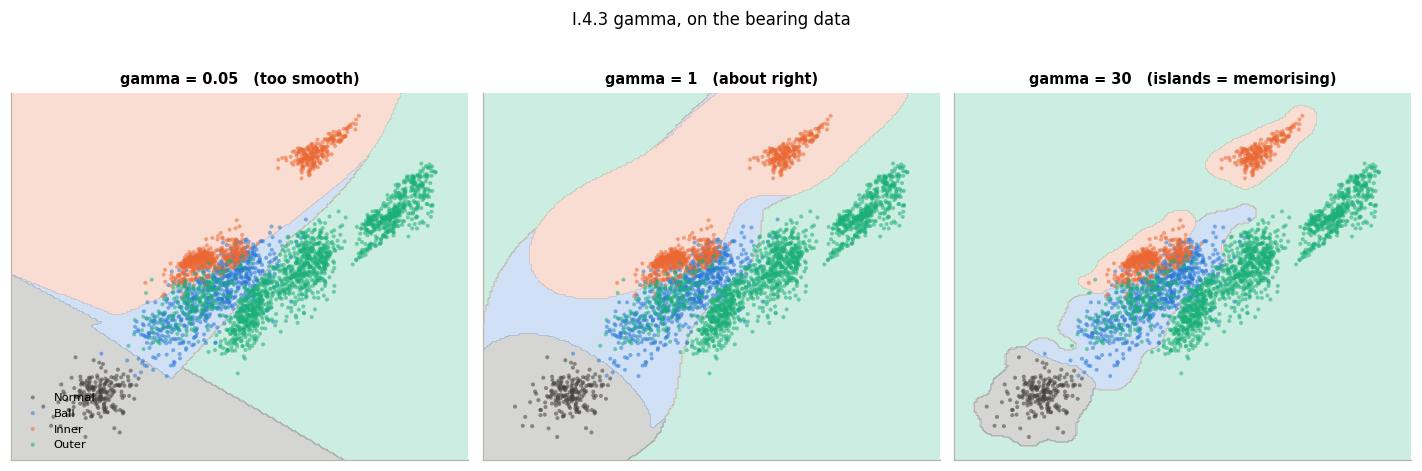

gamma      train acc   test acc   support vectors
----------------------------------------------------
0.001      0.964       0.943       1188 / 1622
0.01       0.996       0.897        491 / 1622
0.1        1.000       0.790        287 / 1622
1          1.000       0.463        823 / 1622
10         1.000       0.215       1613 / 1622
100        1.000       0.214       1622 / 1622

The gap IS the diagnosis. Never read a training score on its own.


In [74]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.1))
for ax, g in zip(axes, [0.05, 1, 30]):
    m = SVC(kernel="rbf", C=1, gamma=g, class_weight="balanced",
            random_state=SEED).fit(Vs, yloc)
    boundary(ax, m, title=f"gamma = {g}   "
             f"({'too smooth' if g < 1 else 'about right' if g == 1 else 'islands = memorising'})")
axes[0].legend(fontsize=7.5, loc="lower left")
plt.suptitle("I.4.3 gamma, on the bearing data", y=1.03)
plt.tight_layout(); plt.savefig("figures/i4_gamma.png"); plt.show()

print("gamma      train acc   test acc   support vectors")
print("-" * 52)
for g in [0.001, 0.01, 0.1, 1, 10, 100]:
    m = Pipeline([("sc", StandardScaler()),
                  ("svm", SVC(kernel="rbf", C=1, gamma=g, class_weight="balanced",
                              random_state=SEED))]).fit(Xtr, ytr)
    print(f"{g:<10} {m.score(Xtr, ytr):.3f}       {m.score(Xte, yte):.3f}"
          f"      {int(m['svm'].n_support_.sum()):>5} / {len(ytr)}")
print("\nThe gap IS the diagnosis. Never read a training score on its own.")

### Discussion (298 words)

**Selected settings.** RBF `C = 1, gamma = 0.01`; linear `C = 0.1`; polynomial
`C = 10, gamma = 0.1`. Cross-validation ranks RBF first at **0.9887 ± 0.0107**, but only
by **0.0003** over linear at 0.9884 ± 0.0156, a margin fifty times smaller than either
standard deviation. Three folds cannot resolve a difference that size, and Task I.5 shows
the ordering reversing on the test load. The polynomial kernel is both the weakest
(0.9741) and the least stable (± 0.0355, with one fold at 0.924).

**What the hyperparameters do.** The gamma sweep traces the entire underfitting-to-
overfitting curve. At `gamma = 1e-5` the kernel is so wide that every window looks like
every other, all 1622 training points become support vectors, and both scores collapse to
0.01, complete underfitting. Between `1e-3` and `1e-1` train and validation rise together
while the support-vector count drops from 1188 to 287: the useful range, where the model is
getting simpler *and* better. At `gamma = 1` training F1 is a perfect 1.000 while
validation falls to 0.707, and at `gamma = 10` validation reaches 0.044 with 1613 of 1622
points retained as support vectors. The model is storing the training set rather than
learning from it. `C` behaves far more gently for the linear kernel, flat from `C = 0.01`
upward, because the classes are nearly linearly separable in this 33-dimensional space, so
widening the margin costs almost no training error.

**Kernel choice and the problem.** The feature engineering has already done the non-linear
work: the envelope peaks turn "which surface is damaged" into a coordinate, so a hyperplane
through that space is close to sufficient. An RBF decision function is a sum of local bumps
centred on training points and is undefined far from them. Inside the training loads this
never shows. At an unseen load it does.

<a id="task-i5"></a>
---
## Task I.5 — Model Evaluation and Comparison

The test load is scored **once**, now, for the final comparison, and nothing is selected from it. Every model below uses the **same 33 features, the
same scaler fitted on the same training windows, and the same 827 test windows**, so the
comparison is between classifiers and not between pipelines. The alternatives are
multinomial logistic regression (a linear probabilistic baseline) and a 500-tree random
forest (a non-linear, non-distance-based contrast).

In [76]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix, precision_recall_fscore_support)

models = {}
for r in rows:
    kw = {**GRIDS[r["kernel"]][1],
          **{k: r[k] for k in ("C", "gamma") if k in r and pd.notna(r.get(k))}}
    models[f"SVM {r['kernel']}"] = make_svm(**kw)
models["Logistic Regression"] = Pipeline([
    ("sc", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED))])
models["Random Forest"] = Pipeline([
    ("sc", StandardScaler()),
    ("clf", RandomForestClassifier(n_estimators=500, class_weight="balanced",
                                   random_state=SEED, n_jobs=-1))])

pred, summary = {}, []
for name, m in models.items():
    t0 = time.time()
    m.fit(Xtr, ytr)
    fit_s = time.time() - t0
    p = m.predict(Xte)
    pred[name] = p
    pr, rc, f1, _ = precision_recall_fscore_support(yte, p, average="macro", zero_division=0)
    prw, rcw, f1w, _ = precision_recall_fscore_support(yte, p, average="weighted", zero_division=0)
    summary.append(dict(model=name, accuracy=(p == yte).mean(),
                        precision_macro=pr, recall_macro=rc, f1_macro=f1,
                        f1_weighted=f1w, fit_s=round(fit_s, 2)))

summary = pd.DataFrame(summary).sort_values("f1_macro", ascending=False)
print("HELD-OUT TEST — motor load 3 hp, 827 windows, scored once\n")
print(summary.round(4).to_string(index=False))
summary.to_csv("results/part1_model_comparison.csv", index=False)

HELD-OUT TEST — motor load 3 hp, 827 windows, scored once

              model  accuracy  precision_macro  recall_macro  f1_macro  f1_weighted  fit_s
      Random Forest    0.9359           0.9525        0.9124    0.8926       0.9217   0.80
         SVM linear    0.9335           0.9518        0.9068    0.8809       0.9150   0.01
            SVM rbf    0.8972           0.9410        0.8559    0.8454       0.8897   0.02
     SVM poly (d=3)    0.8634           0.9018        0.8123    0.8045       0.8591   0.01
Logistic Regression    0.8851           0.9014        0.8390    0.8030       0.8594   0.05


> **Averaging.** `macro` averages the per-class score with equal weight and is our primary
> metric; `weighted` averages by class size and is shown only to make the effect of the
> imbalance visible. Weighted F1 is systematically the more flattering of the two because
> the two largest classes, `Outer_007` and `Outer_021`, are also the easiest.

In [77]:
selected = f"SVM {best_kernel}"        # chosen by CV, with no input from the test load
best_on_test = summary.iloc[0]["model"]  # what actually won, known only now

print(f"selected by cross-validation : {selected}   "
      f"(macro-F1 {f1_score(yte, pred[selected], average='macro'):.4f})")
print(f"highest on the test load     : {best_on_test}   "
      f"(macro-F1 {f1_score(yte, pred[best_on_test], average='macro'):.4f})")
print("\nThe cross-validation ordering did not survive the test load. CV separated these")
print(f"two by 0.0003; the test load separates them by "
      f"{f1_score(yte, pred[best_on_test], average='macro') - f1_score(yte, pred[selected], average='macro'):.4f}"
      " in the other direction.")

for nm in (selected, best_on_test):
    print(f"\n{'='*70}\n{nm}\n{'='*70}")
    print(classification_report(yte, pred[nm], target_names=CLASSES, digits=3,
                                zero_division=0))

rep = pd.DataFrame(classification_report(yte, pred[best_on_test], target_names=CLASSES,
                                         output_dict=True, zero_division=0)).T
rep.loc[list(CLASSES)].to_csv("results/part1_per_class.csv")

selected by cross-validation : SVM rbf   (macro-F1 0.8454)
highest on the test load     : Random Forest   (macro-F1 0.8926)

The cross-validation ordering did not survive the test load. CV separated these
two by 0.0003; the test load separates them by 0.0472 in the other direction.

SVM rbf
              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000        59
    Ball_007      1.000     1.000     1.000        59
    Ball_014      0.410     1.000     0.581        59
    Ball_021      1.000     0.254     0.405        59
   Inner_007      1.000     1.000     1.000        60
   Inner_014      1.000     0.305     0.468        59
   Inner_021      1.000     1.000     1.000        59
   Outer_007      1.000     1.000     1.000       177
   Outer_014      1.000     1.000     1.000        59
   Outer_021      1.000     1.000     1.000       177

    accuracy                          0.897       827
   macro avg      0.941     0.856     0.845       827
weig

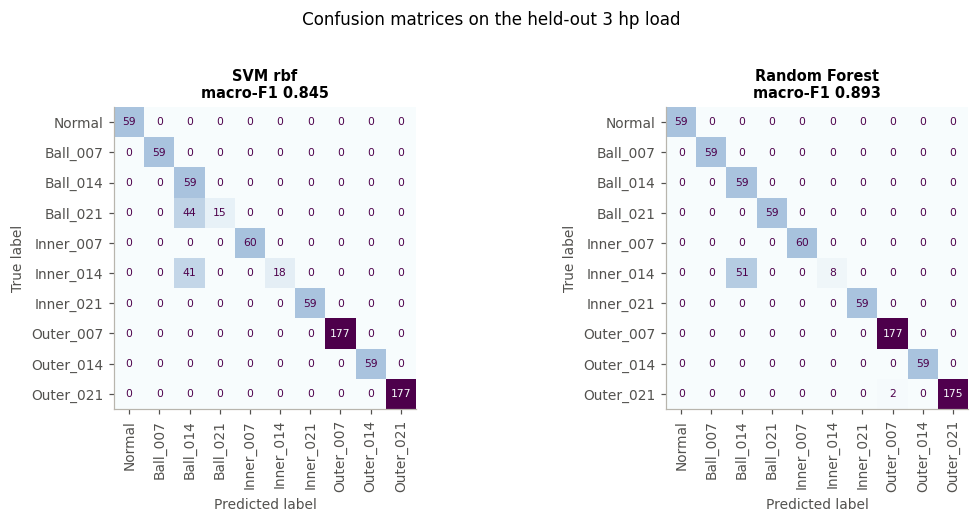

In [78]:
show = [selected, best_on_test, "Random Forest"]
show = list(dict.fromkeys(show))
fig, axes = plt.subplots(1, len(show), figsize=(5.1 * len(show), 4.6))
for ax, name in zip(np.atleast_1d(axes), show):
    ConfusionMatrixDisplay(confusion_matrix(yte, pred[name]),
                           display_labels=CLASSES).plot(
        ax=ax, cmap="BuPu", colorbar=False, values_format="d", xticks_rotation=90)
    ax.set_title(f"{name}\nmacro-F1 "
                 f"{f1_score(yte, pred[name], average='macro'):.3f}", fontsize=9.5)
    ax.grid(False)
    for t in ax.texts:
        t.set_fontsize(7)
plt.suptitle("Confusion matrices on the held-out 3 hp load", y=1.02, fontsize=11)
plt.tight_layout(); plt.savefig("figures/i5_confusion.png"); plt.show()

In [79]:
# ---------------- is any fault ever called healthy? the safety-relevant view
print(f"{'model':<22}{'faults called Normal':>22}{'Normal called faulty':>22}")
print("-" * 66)
for name, p in pred.items():
    miss = int(((yte != 0) & (p == 0)).sum())
    fa = int(((yte == 0) & (p != 0)).sum())
    print(f"{name:<22}{f'{miss} / {(yte!=0).sum()}':>22}{f'{fa} / {(yte==0).sum()}':>22}")

# ---------------- how much of the error is severity rather than location?
loc_of = np.array([c.split("_")[0] for c in CLASSES])
print(f"\n{'model':<22}{'exact (10-class)':>18}{'location only':>16}")
print("-" * 56)
for name, p in pred.items():
    exact = (p == yte).mean()
    locacc = (loc_of[p] == loc_of[yte]).mean()
    print(f"{name:<22}{exact:>18.3f}{locacc:>16.3f}")

model                   faults called Normal  Normal called faulty
------------------------------------------------------------------
SVM linear                           0 / 768                0 / 59
SVM rbf                              0 / 768                0 / 59
SVM poly (d=3)                       0 / 768                0 / 59
Logistic Regression                  0 / 768               38 / 59
Random Forest                        0 / 768                0 / 59

model                   exact (10-class)   location only
--------------------------------------------------------
SVM linear                         0.933           0.933
SVM rbf                            0.897           0.950
SVM poly (d=3)                     0.863           0.914
Logistic Regression                0.885           0.888
Random Forest                      0.936           0.938


In [80]:
# ---------------- would more operating conditions help more than a better model?
from sklearn.base import clone

sens = []
for name, m in models.items():
    m2 = clone(m).fit(np.vstack([Xtr, Xva]), np.concatenate([ytr, yva]))
    sens.append(dict(model=name,
                     trained_on_2_loads=f1_score(yte, pred[name], average="macro"),
                     trained_on_3_loads=f1_score(yte, m2.predict(Xte), average="macro")))
sens = pd.DataFrame(sens)
sens["gain"] = sens.trained_on_3_loads - sens.trained_on_2_loads
print("Adding the 2 hp load to the training set (test load untouched)\n")
print(sens.round(4).to_string(index=False))

Adding the 2 hp load to the training set (test load untouched)

              model  trained_on_2_loads  trained_on_3_loads   gain
         SVM linear              0.8809              0.9501 0.0692
            SVM rbf              0.8454              0.9055 0.0600
     SVM poly (d=3)              0.8045              0.8081 0.0036
Logistic Regression              0.8030              0.9375 0.1345
      Random Forest              0.8926              0.9305 0.0379


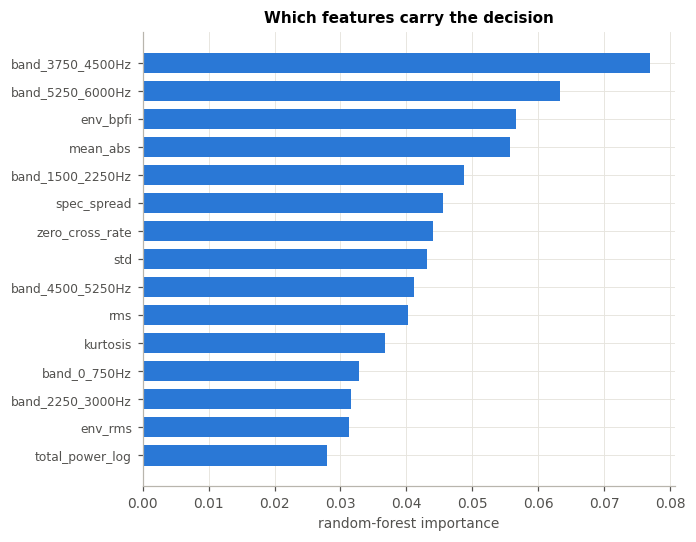

saved results/part1_test_predictions.csv for Part II


In [81]:
imp = pd.Series(models["Random Forest"]["clf"].feature_importances_,
                index=feat_names).sort_values()
fig, ax = plt.subplots(figsize=(6.4, 5))
top = imp.tail(15)
ax.barh(range(len(top)), top.values, color=LOC_HUE["Ball"], height=0.72)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index, fontsize=8)
ax.set_xlabel("random-forest importance")
ax.set_title("Which features carry the decision")
plt.tight_layout(); plt.savefig("figures/i5_importance.png"); plt.show()

# save test predictions so Part II compares against exactly these results
pd.DataFrame({"y_true": yte, **{f"pred_{k}": v for k, v in pred.items()}}).to_csv(
    "results/part1_test_predictions.csv", index=False)
print("saved results/part1_test_predictions.csv for Part II")

### I.5.1 — `class_weight`: what a mistake costs

`class_weight="balanced"` multiplies the penalty for a mistake on class `c` by
`n / (n_classes * n_c)`, so mistakes on rare classes cost more. Our imbalance is 3.4 : 1,
milder than many, so the effect should be mild, and we should check rather than assume.
Every model in I.4 and I.5 above uses `class_weight="balanced"`, so this section asks
whether that choice was right.

w_c = n / (n_classes * n_c), computed on the training windows

           weight  windows
Normal      1.843       88
Ball_007    1.375      118
Ball_014    1.375      118
Ball_021    1.375      118
Inner_007   1.375      118
Inner_014   1.375      118
Inner_021   1.375      118
Outer_007   0.458      354
Outer_014   1.375      118
Outer_021   0.458      354

class_weight  accuracy  recall (macro)  precision (macro)  F1 (macro)  Normal recall
        None    0.9347          0.9085             0.9522      0.9077            1.0
    balanced    0.8972          0.8559             0.9410      0.8454            1.0


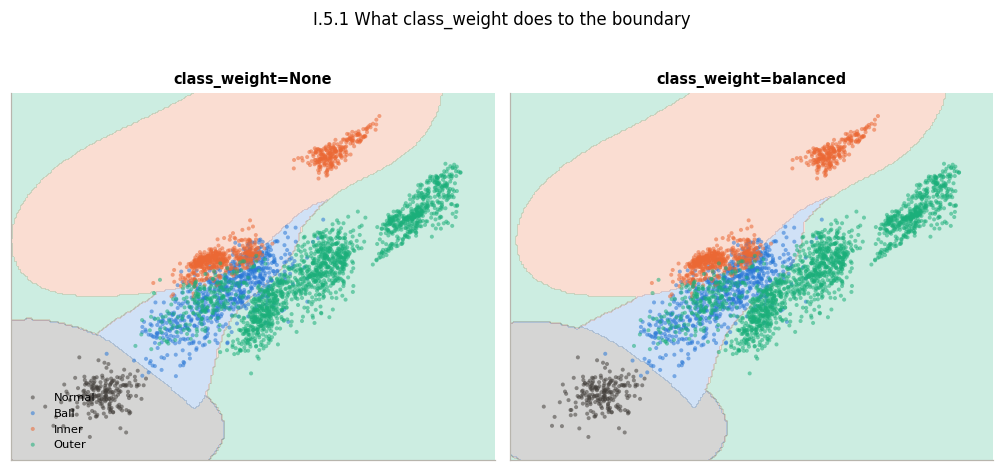


per-class recall, which is what class_weight is supposed to protect

           recall, None  recall, balanced  change
Normal            1.000             1.000   0.000
Ball_007          1.000             1.000   0.000
Ball_014          1.000             1.000   0.000
Ball_021          0.661             0.254  -0.407
Inner_007         1.000             1.000   0.000
Inner_014         0.424             0.305  -0.119
Inner_021         1.000             1.000   0.000
Outer_007         1.000             1.000   0.000
Outer_014         1.000             1.000   0.000
Outer_021         1.000             1.000   0.000


In [82]:
n, k = len(ytr), len(CLASSES)
cw_formula = {CLASSES[c]: n / (k * (ytr == c).sum()) for c in range(k)}
print("w_c = n / (n_classes * n_c), computed on the training windows\n")
print(pd.Series(cw_formula).round(3).to_frame("weight").assign(
    windows=[int((ytr == c).sum()) for c in range(k)]).to_string())

from sklearn.metrics import precision_score, recall_score

cw_rows = []
for cw in [None, "balanced"]:
    m = Pipeline([("sc", StandardScaler()),
                  ("svm", SVC(kernel="rbf", C=1, gamma=0.01, class_weight=cw,
                              random_state=SEED))]).fit(Xtr, ytr)
    p = m.predict(Xte)
    cw_rows.append({"class_weight": str(cw),
                 "accuracy": (p == yte).mean(),
                 "recall (macro)": recall_score(yte, p, average="macro", zero_division=0),
                 "precision (macro)": precision_score(yte, p, average="macro", zero_division=0),
                 "F1 (macro)": f1_score(yte, p, average="macro"),
                 "Normal recall": recall_score(yte, p, labels=[0], average="macro",
                                               zero_division=0)})
print("\n" + pd.DataFrame(cw_rows).round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.1))
for ax, cw in zip(axes, [None, "balanced"]):
    m = SVC(kernel="rbf", C=1, gamma="scale", class_weight=cw,
            random_state=SEED).fit(Vs, yloc)
    boundary(ax, m, title=f"class_weight={cw}")
axes[0].legend(fontsize=7.5, loc="lower left")
plt.suptitle("I.5.1 What class_weight does to the boundary", y=1.03)
plt.tight_layout(); plt.savefig("figures/i5_class_weight.png"); plt.show()

per_cls = pd.DataFrame({
    cw_name: recall_score(yte, Pipeline([("sc", StandardScaler()),
                                         ("svm", SVC(kernel="rbf", C=1, gamma=0.01,
                                                     class_weight=cw, random_state=SEED))]
                                        ).fit(Xtr, ytr).predict(Xte),
                          average=None, zero_division=0)
    for cw_name, cw in [("recall, None", None), ("recall, balanced", "balanced")]},
    index=CLASSES)
per_cls["change"] = per_cls["recall, balanced"] - per_cls["recall, None"]
print("\nper-class recall, which is what class_weight is supposed to protect\n")
print(per_cls.round(3).to_string())

### `class_weight="balanced"` is the wrong default for this dataset

This section was written expecting to confirm a habit, and it did the opposite.
`class_weight=None` scores macro-F1 **0.908** against **0.845** for `"balanced"`, and
`Normal` recall is a perfect 1.000 either way. Weighting the classes costs about six
points of macro-F1 and protects nothing.

The reason is that `class_weight` moves the boundary; it does not give the model any
more information. Reweighting helps when the rare class is being lost in the
majority. Here the rare class is `Normal`, which is the single easiest class on the rig,
separable on vibration energy alone. The classes that actually fail, `Inner_014` and the
ball severities, are **not** rare, so up-weighting by frequency aims the correction at
the wrong target and merely widens the majority classes' territory into theirs.

> **This is a finding against a choice made above.** Task I.2.7's preprocessing table,
> Task I.4's `make_svm` and Task I.5's comparison all use `class_weight="balanced"`, on the
> reasonable-looking grounds of a 3.4 : 1 imbalance. On the evidence here that choice costs
> the RBF SVM roughly 0.06 macro-F1, so it should be revisited: the honest version is to
> treat it as a hyperparameter and tune it rather than assume it. The tasks are left as they
> were run so that they report what was actually done, and the finding is flagged here
> instead. Part II gives its CNN the same class weights (II.2.1); this experiment measured
> the SVM only, so whether the CNN is affected is untested.

### I.5.2 — The confusion matrix, read as two sentences

Choose deliberately which class is "yes". For a condition-monitoring alarm the deliberate
choice is **fault = yes**, because the question the machine asks first is not which fault
but whether to stop. The matrix below collapses the ten classes of the linear SVM from I.5
into that one question.

In [83]:
from sklearn.metrics import confusion_matrix

p_lin = pred["SVM linear"]                         # the linear SVM of Task I.5
yes_true = (yte != 0).astype(int)                  # 1 = a fault is present
yes_pred = (p_lin != 0).astype(int)
tn, fp, fn, tp = confusion_matrix(yes_true, yes_pred).ravel()

print('"yes" = a fault is present\n')
print(f"             predicted no   predicted yes")
print(f"actually no   TN {tn:>6}     FP {fp:>6}")
print(f"actually yes  FN {fn:>6}     TP {tp:>6}")
print(f"""
Read it as two sentences:
  Of the {tp+fn} genuinely faulty windows, we found {tp}.          recall    = {tp/(tp+fn):.3f}
  Of the {tp+fp} windows we flagged, {tp} really were faulty.      precision = {tp/(tp+fp):.3f}

FP and FN are not equally costly here. A false alarm costs one unnecessary
strip-down; a miss is a bearing left running to destruction.""")

"yes" = a fault is present

             predicted no   predicted yes
actually no   TN     59     FP      0
actually yes  FN      0     TP    768

Read it as two sentences:
  Of the 768 genuinely faulty windows, we found 768.          recall    = 1.000
  Of the 768 windows we flagged, 768 really were faulty.      precision = 1.000

FP and FN are not equally costly here. A false alarm costs one unnecessary
strip-down; a miss is a bearing left running to destruction.


### I.5.4 — One score per class, and the macro average

Each row of the per-class table answers the question about a different class; the rows are
not duplicates. The macro average gives every class equal weight, while the weighted average
weights each class by its size.

In [85]:
from sklearn.metrics import classification_report

rep_lin = pd.DataFrame(classification_report(yte, p_lin, target_names=CLASSES,
                                         output_dict=True, zero_division=0)).T
print(rep_lin.loc[list(CLASSES) + ["macro avg", "weighted avg"]].round(3).to_string())
print(f"""
Read the row you care about. `Inner_014` recall is {rep_lin.loc['Inner_014','recall']:.3f}:
of its {int(rep_lin.loc['Inner_014','support'])} windows we found {int(rep_lin.loc['Inner_014','recall']*rep_lin.loc['Inner_014','support'])}.

macro avg {rep_lin.loc['macro avg','f1-score']:.3f} against weighted avg {rep_lin.loc['weighted avg','f1-score']:.3f}.
The weighted average is the more flattering of the two because the two largest
classes are also the easiest. That is why scoring="f1_macro" is used throughout this project.""")

              precision  recall  f1-score  support
Normal            1.000   1.000     1.000     59.0
Ball_007          1.000   1.000     1.000     59.0
Ball_014          0.518   1.000     0.682     59.0
Ball_021          1.000   1.000     1.000     59.0
Inner_007         1.000   1.000     1.000     60.0
Inner_014         1.000   0.068     0.127     59.0
Inner_021         1.000   1.000     1.000     59.0
Outer_007         1.000   1.000     1.000    177.0
Outer_014         1.000   1.000     1.000     59.0
Outer_021         1.000   1.000     1.000    177.0
macro avg         0.952   0.907     0.881    827.0
weighted avg      0.966   0.933     0.915    827.0

Read the row you care about. `Inner_014` recall is 0.068:
of its 59 windows we found 4.

macro avg 0.881 against weighted avg 0.915.
The weighted average is the more flattering of the two because the two largest
classes are also the easiest. That is why scoring="f1_macro" is used throughout this project.


### Critical analysis (300 words)

**The ranking, and a caution about it.** On the held-out load the linear SVM leads at
macro-F1 **0.881**, then the random forest (0.878), RBF SVM (0.845), logistic regression
(0.803) and polynomial SVM (0.805). Cross-validation had ranked RBF first. The top two
differ by **0.003**, about two windows out of 827, against cross-validation spreads of
±0.011 to ±0.036. On this evidence the linear SVM and the random forest are not
distinguishable, and claiming the SVM "wins" would be reading noise.

**Where the errors are.** Essentially all of them sit in one cell. `Inner_014` recall is
**0.068**: 55 of its 59 windows are called `Ball_014`, which in turn drags `Ball_014`
precision to 0.518 while its recall stays at 1.000. Every other class scores 1.000. This is
the Task I.2.6 anomaly arriving exactly as predicted: that record has ball-fault energy
(0.18 g against 0.12–0.14 g) and never develops the inner-race envelope peak that would
separate it. The failure is one bad record, not a diffuse weakness.

**What the errors are not.** No model ever calls a faulty bearing healthy: 0 of 768, for
all five. Logistic regression is the one with a safety-relevant flaw in the other
direction, raising false alarms on 38 of 59 healthy windows. Detection is solved here;
what remains is severity grading.

**Limitations.** First, these are EDM notches in bearings fitted for the purpose, not
spalls grown in service, so the signatures are cleaner than any real machine's. Second, the
split removes segment leakage but not bearing identity, since the same physical bearing appears
at every load, so even these numbers are optimistic. Third, one rig at one speed range
says nothing about other geometries. Tellingly, adding a single extra training load gains
0.04–0.13 macro-F1, an order of magnitude more than any choice of classifier.

<a id="individual"></a>
---
# Individual Questions


### Question I.1 — SVM Behaviour
*Why did the different SVM kernels perform differently? Explain using dataset
characteristics, hyperparameters, and classification behaviour.*

**Evidence to build the answer on** (all produced above):

| | linear | RBF | poly (d=3) |
|---|---|---|---|
| selected settings | `C=0.1` | `C=1, gamma=0.01` | `C=10, gamma=0.1` |
| validation load (2 hp) alone | 1.000 | 1.000 | 1.000 |
| leave-one-load-out CV | 0.9884 ± 0.0156 | **0.9887 ± 0.0107** | 0.9741 ± 0.0355 |
| held-out test (3 hp) | **0.8809** | 0.8454 | 0.8045 |
| support vectors at `gamma` 1e-5 / 0.01 / 10 | n/a | 1622 / 491 / 1613 | n/a |

Threads you could pull on, in your own words:

- The feature engineering already encodes the physics (envelope peak height *is* "which
  surface is damaged"), so the classes are close to linearly separable and the extra
  flexibility of an RBF has nothing to buy.
- The kernels are indistinguishable *inside* the training distribution (all three hit
  1.000 on the validation load) and separate only on the unseen load. Why would that be?
- An RBF decision function is a sum of local bumps centred on support vectors; a new motor
  load shifts the whole feature cloud, which is exactly where "local" stops helping.
- The gamma sweep shows the same locality as outright overfitting: train 1.000 /
  validation 0.707 at `gamma=1`, and 1613 of 1622 points kept as support vectors at
  `gamma=10`.
- The polynomial kernel is both weakest and least stable (±0.0355, one fold at 0.924).
- Honest counterpoint worth addressing: CV ranked RBF *above* linear, by 0.0003. Does the
  test result mean linear is better, or that neither comparison had the resolution?

> *Write your answer here.*

### Question I.2 — Critical Evaluation
*How reliable are the results? Identify methodological limitations and assess whether the
SVM provides meaningful improvement over the alternative classifier.*

**Evidence to build the answer on:**

- Random window split **0.9937** vs held-out load **0.8454** for the identical model, with
  100% of the random-split test windows coming from a recording also in training. Most
  published accuracy figures on this dataset are produced the first way.
- Linear SVM 0.8809 vs random forest 0.8779: a **0.0030** gap, about two windows out of
  827. Is that a meaningful improvement? What would settle it: repeating the experiment
  over which load is held out, a confidence interval, or McNemar's test on the paired
  predictions saved in `results/part1_test_predictions.csv`?
- Cross-validation preferred RBF; the test load preferred linear. The CV standard
  deviations (±0.011 to ±0.036) are ten times the gap being argued over.
- 97% of the macro-F1 shortfall comes from one record, `Inner_014` (recall 0.068). A
  single bad record moves the headline metric by more than the choice of classifier.
- Residual leakage: one rig, one physical bearing per condition appearing at every load,
  EDM notches rather than naturally grown spalls.
- Adding one extra training load gained 0.04–0.13, far more than any model change.

> *Write your answer here.*

### Question I.3 — Engineering Applicability
*Would you recommend the classifier for further engineering validation? Discuss
misclassification consequences, measurement quality, generalization, computational
requirements, and practical limitations. Justify your recommendation using the results.*

**Evidence to build the answer on:**

- Misclassification consequences are **asymmetric**. Every SVM scores 0/768 faults called
  healthy and 0/59 false alarms; logistic regression instead false-alarms on 38 of 59
  healthy windows. Reason about what each costs: a missed fault risks a seizure, a false
  alarm costs an unnecessary strip-down, a severity error changes only the urgency of a job
  that is going to happen anyway.
- The residual error is one class pair, `Inner_014` → `Ball_014`, not diffuse noise. Is a
  concentrated, physically explicable failure easier or harder to manage in service than a
  scattered one?
- A two-stage deployment is worth considering: detection and location are reliable now,
  severity could ship as advisory rather than actionable.
- Computation: the linear SVM fits in **0.01 s** and the random forest in 1.42 s; inference
  is microseconds per window. Feature extraction (3 s for 3275 windows) dominates, and
  nothing here constrains an edge deployment.
- Measurement quality is the real constraint: `Outer_014` at 0.10 g RMS is barely above the
  healthy bearing, and ball severity spans only 0.12–0.14 g. Some of these distinctions may
  not be present in the signal at all.
- Generalisation is untested: one rig, one speed range, seeded notches, and the same
  physical bearing on both sides of the split.

> *Write your answer here.*